# OptiEnergy AI
### Optimization algorithms, temporal validation, and honest energy forecasts

**Research question:** How do optimizer choice, numerical conditioning, feature information, and temporal distribution changes affect household next-hour prediction?

This is a notebook-first portfolio project with two clearly separated studies:

1. **Optimization lab:** eight methods, paired initialization, explicit computation budgets, numerical gradient checks, three seeds, and one-factor sensitivity studies.
2. **Forecasting benchmark:** three calendar validation folds spanning later seasons, a separate inner checkpoint period, a final later-period holdout, seasonal naive references, direct regression and boosted-tree baselines, feature ablation, and paired temporal uncertainty analysis.

**Run it:** Open in Colab, JupyterLab, or VS Code and run cells in order. The notebook automatically downloads the public UCI dataset and caches it; no project upload or archive is needed. All model code is visible in ordinary Python cells. Default execution uses a CPU. The larger full optimizer sensitivity grid is opt-in.

**Read it on GitHub:** Tables and figures below contain executed measurements. Static figures are the primary output; optional interactive Plotly views can be enabled near the end. There are no embedded source-code dictionaries, model binaries, or base64 dataset blobs.

**Important interpretation:** The optimization lab's small early-window result is exploratory. The later forecasting benchmark has its own training, selection and holdout protocol. Its model families have different tuning/training procedures and do not form a controlled optimizer ranking. One household is insufficient evidence for population generalization.

**Data:** Hebrail & Berard (2006), [UCI Household Electric Power Consumption](https://doi.org/10.24432/C58K54), CC BY 4.0. The raw source checksum and software environment are recorded with each run.

## Reading guide and hypotheses

| Question | Evidence | Claim boundary |
|---|---|---|
| Does an update rule learn efficiently? | Loss versus data passes, updates, gradients, seconds | Same family, initialization, objective and baseline controls |
| Does scaling change numerical behavior? | Hessian spectrum and one-factor sensitivity | A stable full-data GD bound does not certify SGD stability |
| Does the predictor generalize over time? | Three later calendar folds and a final period | One household; no test-driven tuning |
| Do lagged observations add information? | Fixed-alpha feature-group ablations on identical validation rows | Predictive association, not causality |
| Is the improvement stable across the held-out period? | Paired moving-calendar-day bootstrap at 1/7/14-day block lengths | Approximate metric uncertainty, not a prediction interval |

The expected outcomes are hypotheses, not predeclared winners. All attempted optimizer runs—including divergence—remain in the exported logs. A top test score never changes the model chosen by validation.

**Runtime profiles:** default `portfolio` executes the full temporal benchmark and the lightweight optimizer lab. For continuous integration, `OPTIENERGY_PROFILE=ci` reduces seeds, epochs, and fitted/evaluated row counts; CI outputs are smoke tests and must not be presented as portfolio measurements.

## 1. Architecture and forecast contract

**Minute kW → validated hourly kWh → causal lag/rolling/calendar inputs → chronological splits → train-only scaling → fixed models and optimizers → validation selection → final test → predictions and reports.**

An observation at index **t = 14:00** describes the finished interval **[13:00, 14:00)**. At origin t, the model predicts energy during **[t, t + 1 hour)**, whose target timestamp is t + 1 hour.

\[
e_t=\frac1{60}\sum_{m\in[t-1h,t)}p_m\ \mathrm{kWh},\qquad \hat y_t=f_\theta(x_t),\quad y_t=e_{t+1}.
\]

Targets require 60 valid minute readings. Short input gaps can forward-fill, but labels are never imputed. All features use data available at the origin. Training labels precede validation origins, validation labels precede test origins, and all transformations fit on training data only.

## 2. Install dependencies

This cell uses the current kernel's Python and installs a dependency only when its installed version is outside the supported range. If a managed Jupyter environment asks you to restart after an installation, restart once and run from the top.

In [1]:
import importlib.metadata as package_metadata
import importlib.util
import subprocess
import sys

try:
    from packaging.requirements import Requirement
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "packaging"], check=True)
    from packaging.requirements import Requirement

DEPENDENCIES = [
    "numpy>=2.1,<3", "pandas>=2.2,<3", "scipy>=1.14,<2", "scikit-learn>=1.6,<2",
    "torch>=2.6,<3", "plotly>=6,<7", "matplotlib>=3.9,<4",
    "joblib>=1.4,<2", "psutil>=6,<8", "threadpoolctl>=3.5,<4",
    "nbformat>=5.10,<6", "pillow>=10,<13",
]
missing = []
for specification in DEPENDENCIES:
    requirement = Requirement(specification)
    try:
        installed = package_metadata.version(requirement.name)
        if not requirement.specifier.contains(installed):
            missing.append(specification)
    except package_metadata.PackageNotFoundError:
        missing.append(specification)
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("Dependencies ready. Python:", sys.version.split()[0])

import matplotlib.pyplot as plt
import plotly.io as pio
from IPython.display import display, Markdown, Image as NotebookImage, FileLink
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

from IPython import get_ipython
notebook_shell = get_ipython()
if notebook_shell is not None:
    notebook_shell.run_line_magic('matplotlib', 'inline')

Dependencies ready. Python: 3.13.2


## 3. Configuration and workspace

Generated CSVs, models, and reports are stored in `OptiEnergy_Notebook_Work/` beside this notebook's working directory. Code is defined directly in the notebook: no `src` package or external project files are needed.

In [2]:
from pathlib import Path
import os
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '1')
PROFILE = os.environ.get('OPTIENERGY_PROFILE', 'portfolio')
if PROFILE not in {'portfolio', 'ci'}:
    raise ValueError('Unknown OPTIENERGY_PROFILE')
NOTEBOOK_ROOT = Path.cwd() / 'OptiEnergy_Notebook_Work'
NOTEBOOK_ROOT.mkdir(parents=True, exist_ok=True)

"""Central, serializable configuration. All paths are relative to this repository."""
from dataclasses import asdict, dataclass
from pathlib import Path

ROOT = NOTEBOOK_ROOT
DATA = ROOT / "data"
RESULTS = ROOT / "results"
MODELS = ROOT / "saved_models"
OPTIMIZERS = ("Batch GD", "SGD", "Mini-batch GD", "Momentum", "Nesterov", "RMSprop", "Adam", "L-BFGS")
SEEDS = (7, 21, 42)


@dataclass(frozen=True)
class TrainConfig:
    model: str = "linear"
    optimizer: str = "Adam"
    lr: float = 0.01
    batch_size: int = 64
    epochs: int = 12
    momentum: float = 0.9
    alpha: float = 0.0
    schedule: str = "constant"
    decay: float = 0.05
    seed: int = 7
    threshold: float = 0.35
    scaling: str = "standard"

    def validate(self):
        if self.model not in {"linear", "ridge", "ann", "sklearn"}:
            raise ValueError("Unknown model")
        if self.optimizer not in OPTIMIZERS and not (self.model == "sklearn" and self.optimizer == "Direct solve"):
            raise ValueError("Unknown optimizer")
        if not 0 < self.lr <= 10 or not 0 <= self.momentum < 1:
            raise ValueError("Require 0 < learning rate <= 10 and 0 <= momentum < 1")
        if self.batch_size < 1 or self.epochs < 1 or self.alpha < 0 or self.decay < 0:
            raise ValueError("Invalid batch size, epochs, regularization, or decay")
        if self.model in {"linear", "sklearn"} and self.alpha != 0:
            raise ValueError("Use model='ridge' for a regularized linear model")
        if self.schedule not in {"constant", "decay"}:
            raise ValueError("Unknown learning-rate schedule")
        if self.scaling not in {"standard", "minmax", "robust", "none"}:
            raise ValueError("Unknown feature scaling")
        return self

    def to_dict(self):
        return asdict(self)

print('Workspace folder:', NOTEBOOK_ROOT.name)

if PROFILE == 'ci':
    SEEDS = (7,)
print('Execution profile:', PROFILE)

Workspace folder: OptiEnergy_Notebook_Work
Execution profile: portfolio


## 4. Reproducibility and result helpers

Set deterministic seeds, hash configurations, record the runtime, and write strict JSON metadata.

In [3]:
import hashlib
import json
import os
import platform
import random
from pathlib import Path

import numpy as np


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    import torch
    torch.manual_seed(seed)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)


def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()[:16]


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, default=str, allow_nan=False), encoding="utf-8")


def environment():
    from importlib.metadata import version
    names = ["numpy", "pandas", "scipy", "scikit-learn", "torch"]
    return {"python": platform.python_version(), "platform": platform.platform(),
            "packages": {n: version(n) for n in names},
            "cpu_count": os.cpu_count(), "torch_threads": 1}

## 5. Official UCI download and hourly aggregation

This is the complete download/cache/validation implementation. It uses the official UCI archive if the hourly cache is absent. Duplicate timestamps, invalid numbers, negative power, missing minutes, and partial hours are handled explicitly.

### Automatic data acquisition

The loader below downloads the official UCI archive only when a valid processed cache is absent. It extracts a single named member, verifies ZIP integrity, and records a SHA-256. Minute power is integrated into hourly energy; incomplete hours never become labels. `FORCE_RAW_REBUILD=True` reconstructs the cache.

In [4]:
"""Download UCI 235 atomically; aggregate complete observed hours without inventing labels."""
import argparse
import hashlib
import json
import shutil
import time
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd


URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
SOURCE = "https://doi.org/10.24432/C58K54"
SCHEMA = "complete-hours-v2"


def download_dataset(directory=DATA / "raw"):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    target = directory / "household_power_consumption.txt"
    if target.exists() and target.stat().st_size > 1_000_000:
        return target
    archive = directory / "uci235.zip"
    if not archive.exists():
        partial = archive.with_suffix(".partial")
        for attempt in range(3):
            try:
                request = urllib.request.Request(URL, headers={"User-Agent": "OptiEnergy-AI/1.0 educational research"})
                with urllib.request.urlopen(request, timeout=120) as response, partial.open("wb") as out:
                    shutil.copyfileobj(response, out)
                with zipfile.ZipFile(partial) as z:
                    if z.testzip():
                        raise ValueError("UCI archive failed its CRC integrity check")
                partial.replace(archive)
                break
            except (OSError, ValueError, zipfile.BadZipFile):
                partial.unlink(missing_ok=True)
                if attempt == 2:
                    raise RuntimeError("Cannot download UCI data. Download the ZIP manually into data/raw/uci235.zip.")
                time.sleep(attempt + 1)
    with zipfile.ZipFile(archive) as z:
        # Read only the named member; never extract arbitrary archive paths.
        member = next((n for n in z.namelist() if Path(n).name == target.name), None)
        if member is None:
            raise ValueError("Dataset file is missing from archive")
        with z.open(member) as source, target.with_suffix(".partial").open("wb") as out:
            shutil.copyfileobj(source, out)
    target.with_suffix(".partial").replace(target)
    return target


def aggregate_minutes(frame):
    """An index at 14:00 represents energy observed in [13:00, 14:00)."""
    frame = frame.copy()
    timestamps = pd.to_datetime(frame["Date"].astype(str) + " " + frame["Time"].astype(str),
                                format="%d/%m/%Y %H:%M:%S", errors="coerce")
    power = pd.to_numeric(frame["Global_active_power"], errors="coerce")
    power = power.where(np.isfinite(power) & (power >= 0))
    series = pd.Series(power.to_numpy(), index=timestamps).loc[timestamps.notna().to_numpy()]
    duplicates = int(series.index.duplicated().sum())
    series = series[~series.index.duplicated(keep="first")].sort_index()
    series = series.asfreq("min")
    groups = series.resample("h", closed="left", label="right")
    counts = groups.count()
    energy = (groups.sum(min_count=60) / 60.0).where(counts == 60)
    hourly = pd.DataFrame({"energy_kwh": energy, "observed_minutes": counts})
    hourly.index.name = "origin"
    stats = {"source": SOURCE, "license": "CC BY 4.0; Hebrail & Berard",
             "raw_rows": len(frame), "duplicate_timestamps": duplicates,
             "missing_or_invalid_minutes": int(series.isna().sum()),
             "missing_minute_fraction": float(series.isna().mean()),
             "hours": len(hourly), "complete_hours": int(energy.notna().sum()),
             "incomplete_hours": int(energy.isna().sum()), "schema": SCHEMA,
             "timestamp_convention": "naive local clock; right endpoint of observed hourly interval"}
    return hourly, stats


def load_hourly(data_dir=DATA, force=False):
    data_dir = Path(data_dir)
    cache, metadata = data_dir / "processed/hourly.csv", data_dir / "processed/metadata.json"
    if cache.exists() and metadata.exists() and not force:
        stats = json.loads(metadata.read_text(encoding="utf-8"))
        if stats.get("schema") == SCHEMA:
            return pd.read_csv(cache, index_col=0, parse_dates=True), stats
    path = download_dataset(data_dir / "raw")
    frame = pd.read_csv(path, sep=";", na_values=["?", ""],
                        usecols=["Date", "Time", "Global_active_power"], low_memory=False)
    hourly, stats = aggregate_minutes(frame)
    stats["raw_sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
    cache.parent.mkdir(parents=True, exist_ok=True)
    hourly.to_csv(cache)
    write_json(metadata, stats)
    return hourly, stats

In [5]:
FORCE_RAW_REBUILD = False
hourly, dataset_metadata = load_hourly(force=FORCE_RAW_REBUILD)
display(pd.DataFrame({
    "Quantity": ["Raw minute records", "Missing or invalid minutes", "Complete observed hours", "Incomplete hours"],
    "Measured value": [dataset_metadata["raw_rows"], dataset_metadata["missing_or_invalid_minutes"],
                       dataset_metadata["complete_hours"], dataset_metadata["incomplete_hours"]],
}))
display(hourly.head())
print("Source:", dataset_metadata["source"])
print("Raw text SHA-256:", dataset_metadata["raw_sha256"])

,Quantity,Measured value
0,Raw minute records,2075259
1,Missing or invalid minutes,25979
2,Complete observed hours,34085
3,Incomplete hours,504


,energy_kwh,observed_minutes
origin,,
2006-12-16 18:00:00,NaN,36
2006-12-16 19:00:00,3.632200,60
2006-12-16 20:00:00,3.400233,60
2006-12-16 21:00:00,3.268567,60
2006-12-16 22:00:00,3.056467,60


Source: https://doi.org/10.24432/C58K54
Raw text SHA-256: 4259c9d7ece5dbee9ab8d53682baac68d791c864f0f64a52b4043cb3b90894b7


## 6. Exploratory data analysis

These full-history summaries are descriptive. They do not choose hyperparameters or alter the experiment's held-out partitions. Hour/day labels use the interval's starting time.

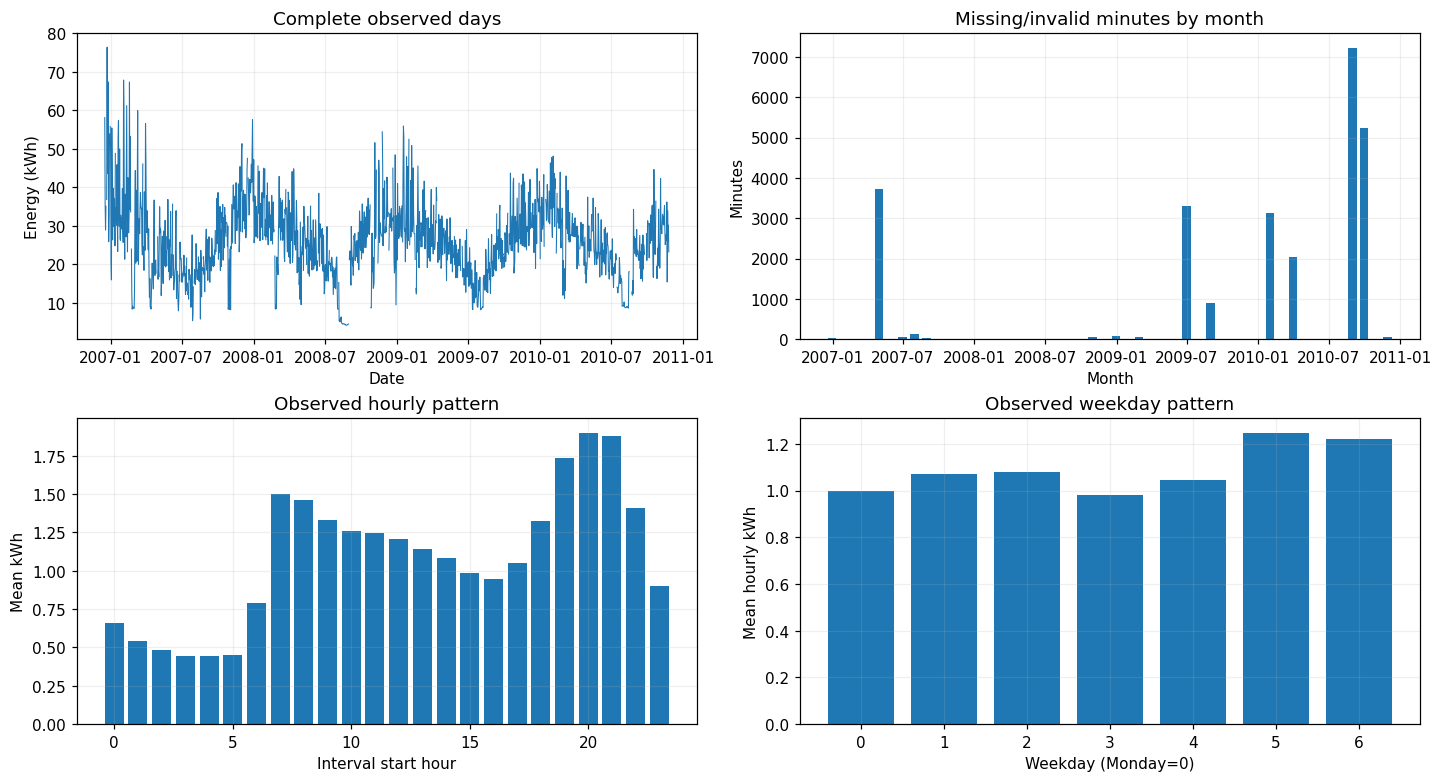

In [6]:
daily_energy = hourly.energy_kwh.resample("D").sum(min_count=24)
fig, axes = plt.subplots(2, 2, figsize=(13, 7), layout="constrained")
axes[0, 0].plot(daily_energy.index, daily_energy, linewidth=.7)
axes[0, 0].set(title="Complete observed days", ylabel="Energy (kWh)", xlabel="Date")
missing_by_month = (60 - hourly.observed_minutes).resample("ME").sum()
axes[0, 1].bar(missing_by_month.index, missing_by_month, width=22)
axes[0, 1].set(title="Missing/invalid minutes by month", ylabel="Minutes", xlabel="Month")
hourly_pattern = hourly.energy_kwh.groupby((hourly.index.hour - 1) % 24).mean()
axes[1, 0].bar(hourly_pattern.index, hourly_pattern)
axes[1, 0].set(title="Observed hourly pattern", xlabel="Interval start hour", ylabel="Mean kWh")
weekday_pattern = hourly.energy_kwh.groupby((hourly.index-pd.Timedelta(hours=1)).dayofweek).mean()
axes[1, 1].bar(weekday_pattern.index, weekday_pattern)
axes[1, 1].set(title="Observed weekday pattern", xlabel="Weekday (Monday=0)", ylabel="Mean hourly kWh")
plt.show()

## 7. Causal feature engineering

Create lags 1/3/6/12/24 hours, rolling mean/std for 3/6/12/24 hours, calendar values, and cyclical encodings. Every feature is available at its stated origin.

In [7]:
"""Every feature at origin t is measurable using hourly observations through t."""
import numpy as np
import pandas as pd

LAGS = (1, 3, 6, 12, 24)
WINDOWS = (3, 6, 12, 24)


def features_at_origins(hourly):
    if not isinstance(hourly.index, pd.DatetimeIndex) or not hourly.index.is_monotonic_increasing:
        raise ValueError("A sorted DatetimeIndex is required")
    if hourly.index.has_duplicates:
        raise ValueError("Duplicate hourly origins are not allowed")
    # Reindex before shifts: a missing clock hour must never become a one-hour lag.
    observed = hourly["energy_kwh"].asfreq("h")
    # Causal bounded forward fill is for INPUTS ONLY. Labels remain strictly observed.
    energy = observed.ffill(limit=6)
    x = pd.DataFrame({"energy_current": energy, "current_missing": observed.isna().astype(float)})
    for lag in LAGS:
        x[f"lag_{lag}"] = energy.shift(lag)
    for window in WINDOWS:
        x[f"rolling_mean_{window}"] = energy.rolling(window, min_periods=window).mean()
        x[f"rolling_std_{window}"] = energy.rolling(window, min_periods=window).std(ddof=0)
    # Calendar covariates describe the next hourly interval, whose left endpoint is t.
    idx = x.index
    x["hour"], x["day"], x["weekday"], x["month"] = idx.hour, idx.day, idx.dayofweek, idx.month
    x["weekend"] = (idx.dayofweek >= 5).astype(float)
    for name, values, period in (("hour", idx.hour, 24), ("weekday", idx.dayofweek, 7), ("month", idx.month - 1, 12)):
        x[name + "_sin"] = np.sin(2 * np.pi * values / period)
        x[name + "_cos"] = np.cos(2 * np.pi * values / period)
    return x.replace([np.inf, -np.inf], np.nan)


def supervised_frame(hourly):
    x = features_at_origins(hourly)
    x["target"] = hourly["energy_kwh"].asfreq("h").shift(-1)
    x["target_time"] = x.index + pd.Timedelta(hours=1)
    return x.dropna().copy()

## 8. Chronological splits and train-only scaling

Create 70/15/15 train/validation/test partitions, purge cross-boundary labels, and fit feature and target transforms on training rows only. The target is standardized for optimization and inverted to kWh for scoring.

In [8]:
from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler



@dataclass
class PreparedData:
    X_train: np.ndarray
    X_val: np.ndarray
    X_test: np.ndarray
    y_train: np.ndarray
    y_val: np.ndarray
    y_test: np.ndarray
    frames: dict
    feature_names: list
    scaler: object
    y_mean: float
    y_std: float
    scaling: str

    def inverse_target(self, y):
        return np.asarray(y) * self.y_std + self.y_mean

    def transform(self, frame):
        x = frame[self.feature_names].to_numpy(dtype=float)
        return self.scaler.transform(x) if self.scaler is not None else x


def prepare_data(hourly, scaling="standard", max_hours=None):
    if scaling not in {"standard", "minmax", "robust", "none"}:
        raise ValueError("Unknown scaling")
    if max_hours is not None:
        if max_hours < 240:
            raise ValueError("Use at least 240 hours")
        hourly = hourly.iloc[:max_hours]
    frame = supervised_frame(hourly)
    if len(frame) < 100:
        raise ValueError("Insufficient complete causal feature/target rows")
    n = len(frame)
    a, b = int(n * .70), int(n * .85)
    train, val, test = frame.iloc[:a].copy(), frame.iloc[a:b].copy(), frame.iloc[b:].copy()
    # A training target cannot land at the first validation origin. Same for val/test.
    train = train.loc[train.target_time < val.index.min()]
    val = val.loc[val.target_time < test.index.min()]
    names = [c for c in frame if c not in {"target", "target_time"}]
    scaler = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}.get(scaling)
    scaler = scaler().fit(train[names].to_numpy(float)) if scaler else None
    transform = lambda f: scaler.transform(f[names].to_numpy(float)) if scaler else f[names].to_numpy(float)
    mean, std = float(train.target.mean()), float(train.target.std(ddof=0))
    std = max(std, 1e-8)
    target = lambda f: (f.target.to_numpy(float) - mean) / std
    return PreparedData(transform(train), transform(val), transform(test),
                        target(train), target(val), target(test),
                        {"train": train, "validation": val, "test": test}, names,
                        scaler, mean, std, scaling)

,partition,rows,first_origin,last_origin,last_target
0,train,1656,2006-12-17 19:00:00,2007-02-24 23:00:00,2007-02-25 00:00:00
1,validation,354,2007-02-25 01:00:00,2007-03-11 18:00:00,2007-03-11 19:00:00
2,test,356,2007-03-11 20:00:00,2007-03-26 16:00:00,2007-03-26 17:00:00


,energy_current,current_missing,lag_1,lag_3,lag_6,lag_12,lag_24,rolling_mean_3,rolling_std_3,rolling_mean_6,...,month,weekend,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos,target,target_time
origin,,,,,,,,,,,,,,,,,,,,,
2006-12-17 19:00:00,3.697100,0.0,3.406767,2.985400,1.915867,1.303300,3.632200,3.476633,0.159340,2.861450,...,12,1.0,-0.965926,0.258819,-0.781831,0.62349,-0.5,0.866025,2.908400,2006-12-17 20:00:00
2006-12-17 20:00:00,2.908400,0.0,3.697100,3.326033,1.660767,1.620033,3.400233,3.337422,0.325698,3.069389,...,12,1.0,-0.866025,0.500000,-0.781831,0.62349,-0.5,0.866025,3.361500,2006-12-17 21:00:00
2006-12-17 21:00:00,3.361500,0.0,2.908400,3.406767,2.092633,1.890567,3.268567,3.322333,0.323174,3.280867,...,12,1.0,-0.707107,0.707107,-0.781831,0.62349,-0.5,0.866025,3.040767,2006-12-17 22:00:00
2006-12-17 22:00:00,3.040767,0.0,3.361500,3.697100,2.985400,2.549067,3.056467,3.103556,0.190231,3.290094,...,12,1.0,-0.500000,0.866025,-0.781831,0.62349,-0.5,0.866025,1.518000,2006-12-17 23:00:00
2006-12-17 23:00:00,1.518000,0.0,3.040767,2.908400,3.326033,3.628900,2.200133,2.640089,0.804168,2.988756,...,12,1.0,-0.258819,0.965926,-0.781831,0.62349,-0.5,0.866025,0.437733,2006-12-18 00:00:00


Number of inputs: 26


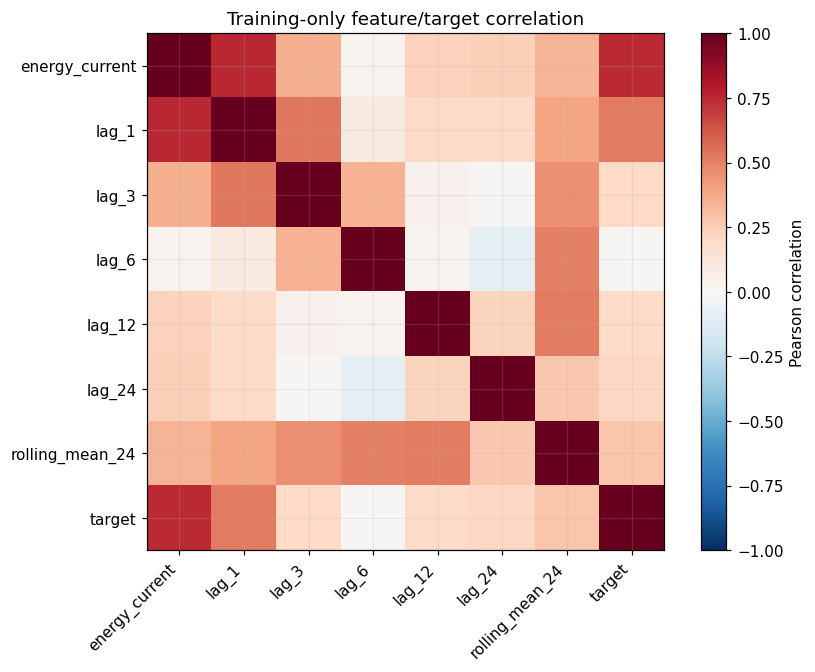

In [9]:
DEMO_HOURS = 2400
preview_data = prepare_data(hourly, scaling="standard", max_hours=DEMO_HOURS)
display(pd.DataFrame([
    {"partition": name, "rows": len(frame), "first_origin": frame.index.min(),
     "last_origin": frame.index.max(), "last_target": frame.target_time.max()}
    for name, frame in preview_data.frames.items()
]))
display(preview_data.frames["train"].head())
print("Number of inputs:", len(preview_data.feature_names))
corr_columns = ["energy_current", "lag_1", "lag_3", "lag_6", "lag_12", "lag_24", "rolling_mean_24", "target"]

correlation = preview_data.frames["train"][corr_columns].corr()
figure, axis = plt.subplots(figsize=(8, 6), layout="constrained")
image = axis.imshow(correlation, vmin=-1, vmax=1, cmap="RdBu_r")
axis.set_xticks(range(len(corr_columns)), corr_columns, rotation=45, ha="right")
axis.set_yticks(range(len(corr_columns)), corr_columns)
axis.set_title("Training-only feature/target correlation")
figure.colorbar(image, ax=axis, label="Pearson correlation")
plt.show()


## 9. Mathematical formulation and models

Append the intercept column to obtain $A\in\mathbb R^{n\times(d+1)}$, and set $D=\mathrm{diag}(1,\ldots,1,0)$.

\[
J(w)=\frac1n\lVert Aw-u\rVert^2+\frac\alpha2w^TDw,\qquad
\nabla J=\frac2nA^T(Aw-u)+\alpha Dw,\qquad
H=\frac2nA^TA+\alpha D.
\]

Linear/ridge squared loss is convex because $v^THv\ge0$. Strict convexity requires a positive-definite Hessian. Constant or redundant features can make the unregularized Hessian singular; ridge adds curvature while leaving the intercept unpenalized.

With $L=\lambda_{\max}(H)$, batch GD is stable for $0<\eta<2/L$ and descends for $\eta\le1/L$. This full-data bound does not guarantee per-sample SGD stability. The fixed ANN is **26 → 32 → 16 → 1**, uses Tanh, and has a non-convex parameter-space loss.

In [10]:
"""Linear MSE and ridge objectives share one analytically differentiated implementation."""
import numpy as np
import torch
from torch import nn


class LinearModel:
    def __init__(self, n_features):
        self.weights = np.zeros(n_features + 1, dtype=np.float64)

    @staticmethod
    def design(X):
        return np.column_stack([X, np.ones(len(X))])

    def predict(self, X):
        return self.design(X) @ self.weights


class RidgeModel(LinearModel):
    """Model form is identical; the trainer adds alpha/2 times squared non-bias weights."""


def linear_objective(weights, X, y, alpha=0.0):
    error = X @ weights - y
    penalty = weights.copy()
    penalty[-1] = 0.0
    loss = np.mean(error ** 2) + alpha * .5 * np.dot(penalty, penalty)
    gradient = 2 * X.T @ error / len(y) + alpha * penalty
    return float(loss), gradient


def linear_hessian(X, alpha=0.0):
    regularizer = np.eye(X.shape[1])
    regularizer[-1, -1] = 0
    return 2 * X.T @ X / len(X) + alpha * regularizer


def gradient_check(weights, X, y, alpha=.1, epsilon=1e-6):
    analytic = linear_objective(weights, X, y, alpha)[1]
    numerical = np.empty_like(weights)
    for j in range(len(weights)):
        step = np.zeros_like(weights)
        step[j] = epsilon
        numerical[j] = (linear_objective(weights + step, X, y, alpha)[0] -
                        linear_objective(weights - step, X, y, alpha)[0]) / (2 * epsilon)
    return float(np.linalg.norm(analytic - numerical) / max(1., np.linalg.norm(analytic), np.linalg.norm(numerical)))


class SmallANN(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features, 32), nn.Tanh(),
                                 nn.Linear(32, 16), nn.Tanh(), nn.Linear(16, 1))

    def forward(self, X):
        return self.net(X).squeeze(-1)

    def predict(self, X):
        self.eval()
        with torch.no_grad():
            return self(torch.as_tensor(X, dtype=torch.float32)).numpy()


def ann_objective(model, X, y, alpha):
    penalty = sum((p ** 2).sum() for name, p in model.named_parameters() if "weight" in name)
    return torch.mean((model(X) - y) ** 2) + alpha * .5 * penalty

In [11]:
design = LinearModel.design(preview_data.X_train)
relative_error = gradient_check(np.zeros(design.shape[1]), design[:50], preview_data.y_train[:50])
hessian = linear_hessian(design)
spectrum = np.linalg.eigvalsh(hessian)
rank_tolerance = spectrum.max() * 1e-10
rank = int(np.sum(spectrum > rank_tolerance))
print(f"Gradient-check relative error: {relative_error:.3e}")
print(f"Hessian numerical rank: {rank}/{len(spectrum)}")
print(f"Largest curvature eigenvalue L: {spectrum.max():.6f}")
print(f"Stable full-batch GD upper step 2/L: {2/spectrum.max():.6f}")
print("Full condition number:", "singular at tolerance" if rank < len(spectrum) else spectrum.max()/spectrum.min())
assert relative_error < 1e-7

Gradient-check relative error: 1.149e-10
Hessian numerical rank: 26/27
Largest curvature eigenvalue L: 12.504830
Stable full-batch GD upper step 2/L: 0.159938
Full condition number: singular at tolerance


## 10. NumPy optimizers from scratch

Batch GD, SGD, and mini-batch GD share the same update equation and differ by batch selection. Momentum stores velocity; Nesterov evaluates a lookahead gradient; RMSprop uses second moments; Adam uses bias-corrected first and second moments. L-BFGS uses SciPy/PyTorch closures in the training engine below.

In [12]:
"""First-order NumPy optimizer classes. Nesterov evaluates the gradient at lookahead()."""
import numpy as np


class GradientDescent:
    def __init__(self, lr=.01, momentum=.9):
        if not np.isfinite(lr) or lr <= 0 or not 0 <= momentum < 1:
            raise ValueError("Invalid optimizer hyperparameters")
        self.lr, self.beta, self.t = lr, momentum, 0

    def lookahead(self, weights):
        return weights

    def step(self, weights, gradient):
        self.t += 1
        return weights - self.lr * gradient


class Momentum(GradientDescent):
    def step(self, weights, gradient):
        self.t += 1
        if not hasattr(self, "velocity"):
            self.velocity = np.zeros_like(weights)
        self.velocity = self.beta * self.velocity - self.lr * gradient
        return weights + self.velocity


class Nesterov(Momentum):
    def lookahead(self, weights):
        return weights + self.beta * getattr(self, "velocity", np.zeros_like(weights))


class RMSprop(GradientDescent):
    def step(self, weights, gradient):
        self.t += 1
        self.square = .99 * getattr(self, "square", np.zeros_like(weights)) + .01 * gradient ** 2
        return weights - self.lr * gradient / (np.sqrt(self.square) + 1e-8)


class Adam(GradientDescent):
    def step(self, weights, gradient):
        self.t += 1
        self.first = .9 * getattr(self, "first", np.zeros_like(weights)) + .1 * gradient
        self.second = .999 * getattr(self, "second", np.zeros_like(weights)) + .001 * gradient ** 2
        first = self.first / (1 - .9 ** self.t)
        second = self.second / (1 - .999 ** self.t)
        return weights - self.lr * first / (np.sqrt(second) + 1e-8)


def make_optimizer(name, lr=.01, momentum=.9):
    cls = {"Batch GD": GradientDescent, "SGD": GradientDescent, "Mini-batch GD": GradientDescent,
           "Momentum": Momentum, "Nesterov": Nesterov, "RMSprop": RMSprop, "Adam": Adam}.get(name)
    if cls is None:
        raise ValueError("L-BFGS uses a function/gradient closure; it is handled by SciPy/PyTorch")
    return cls(lr, momentum)

### Update equations and cost

| Method | Update principle | Linear per-update computation / extra state |
|---|---|---|
| GD / SGD / mini-batch GD | $w\leftarrow w-\eta g$ | $O(bp)$ / $O(p)$ |
| Momentum | $v\leftarrow\beta v-\eta g$; $w\leftarrow w+v$ | $O(bp)$ / $O(p)$ |
| NumPy Nesterov | Evaluate $g$ at $w+\beta v$, then update velocity/weights | $O(bp)$ / $O(p)$ |
| RMSprop | $s\leftarrow.99s+.01g^2$; $w\leftarrow w-\eta g/(\sqrt{s}+\epsilon)$ | $O(bp)$ / $O(p)$ |
| Adam | Moments .9/.999, bias correction per update, adaptive coordinate steps | $O(bp)$ / $O(p)$ |
| L-BFGS | Limited-memory curvature pairs and a line search | $O(qnp+mp)$ / $O(mp)$ |

Here $b$ is batch size, $p$ parameter count, $m=10$ history pairs, and $q$ the number of full-data evaluations for an accepted L-BFGS step. All L-BFGS closure evaluations count toward the training budget. Monitoring overhead is logged separately.

The PyTorch Nesterov implementation uses its standard momentum-buffer convention. Comparisons are within model families; identical NumPy/PyTorch trajectories are not assumed.

## 11. Mathematical benchmark functions

Exact-gradient quadratic, ill-conditioned quadratic (condition number 100), Rosenbrock, and Himmelblau objectives.

In [13]:
import numpy as np


def quadratic(p):
    x, y = p
    return .5 * (x*x + 4*y*y), np.array([x, 4*y])


def ill_conditioned(p):
    x, y = p
    return .5 * (x*x + 100*y*y), np.array([x, 100*y])


def rosenbrock(p):
    x, y = p
    return (1-x)**2 + 100*(y-x*x)**2, np.array([-2*(1-x)-400*x*(y-x*x), 200*(y-x*x)])


def himmelblau(p):
    x, y = p
    a, b = x*x+y-11, x+y*y-7
    return a*a+b*b, np.array([4*x*a+2*b, 2*a+4*y*b])


BENCHMARKS = {"Quadratic": (quadratic, (-4., 4.), (3., 3.), .1),
              "Ill-conditioned quadratic": (ill_conditioned, (-4., 4.), (3., 3.), .01),
              "Rosenbrock": (rosenbrock, (-2., 2.), (-1.2, 1.), .001),
              "Himmelblau": (himmelblau, (-5., 5.), (-3., -3.), .01)}

## 12. Metrics in physical units

MSE is measured in kWh²; RMSE and MAE in kWh. R² can be negative. Repeated-run summaries use sample standard deviation, not a confidence interval.

In [14]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def regression_metrics(actual, predicted):
    if not np.isfinite(predicted).all():
        raise ValueError("Non-finite prediction")
    mse = mean_squared_error(actual, predicted)
    return {"mse": float(mse), "rmse": float(np.sqrt(mse)),
            "mae": float(mean_absolute_error(actual, predicted)), "r2": float(r2_score(actual, predicted))}

## 13. Instrumented linear, ridge, and ANN training

The complete engine below fixes initialization and seeded permutations within each family. It logs objective/validation loss, gradient norm, updates, example-processing passes, function/gradient calls, time, process RSS, and threshold crossing. It restores validation-best checkpoints and never reads test labels.

In [15]:
"""Instrumented CPU training. Validation checkpoints, no test access in this module."""
import copy
import time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import psutil
import torch
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression



class BudgetExhausted(Exception):
    """Expected termination when a quasi-Newton evaluation budget has been spent."""


@dataclass
class TrainingResult:
    model: object
    history: pd.DataFrame
    summary: dict
    config: dict


def train(data, config, progress=None):
    config.validate()
    seed_everything(config.seed)
    rng = np.random.default_rng(config.seed)
    n, d = data.X_train.shape
    X, y, V, v = data.X_train, data.y_train, data.X_val, data.y_val
    ann = config.model == "ann"
    if ann:
        X, y, V, v = [torch.as_tensor(z, dtype=torch.float32) for z in (X, y, V, v)]
        model = SmallANN(d)
    elif config.model == "sklearn":
        model = LinearRegression()
    else:
        model = (RidgeModel if config.model == "ridge" else LinearModel)(d)
        X, V = model.design(X), model.design(V)
    start = time.perf_counter()
    counters = {"updates": 0, "gradient_evaluations": 0, "function_evaluations": 0,
                "processed_examples": 0, "monitor_gradient_evaluations": 0,
                "monitor_function_evaluations": 0}
    rows, best, best_val, best_epoch = [], None, float("inf"), 0
    status, message, threshold_seconds = "budget_completed", "", None
    process = psutil.Process()
    peak_rss = process.memory_info().rss / 2 ** 20

    def state():
        if ann:
            return copy.deepcopy(model.state_dict())
        return copy.deepcopy(model) if config.model == "sklearn" else model.weights.copy()

    def record(epoch):
        nonlocal best, best_val, best_epoch, threshold_seconds, peak_rss
        if ann:
            model.zero_grad()
            objective = ann_objective(model, X, y, config.alpha)
            objective.backward()
            loss = float(objective.detach())
            grad = float(torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters())))
            with torch.no_grad():
                pred, vp = model(X).numpy(), model(V).numpy()
        elif config.model == "sklearn":
            pred, vp = model.predict(X), model.predict(V)
            w = np.r_[model.coef_, model.intercept_]
            loss, g = linear_objective(w, LinearModel.design(X), y)
            grad = float(np.linalg.norm(g))
        else:
            loss, g = linear_objective(model.weights, X, y, config.alpha)
            grad = float(np.linalg.norm(g))
            pred, vp = X @ model.weights, V @ model.weights
        counters["monitor_gradient_evaluations"] += 1
        counters["monitor_function_evaluations"] += 2
        val_mse = float(np.mean((np.asarray(vp) - data.y_val) ** 2))
        train_mse = float(np.mean((np.asarray(pred) - data.y_train) ** 2))
        if not np.isfinite([loss, val_mse, grad]).all() or loss > 1e12:
            raise FloatingPointError("Non-finite or exploding training objective")
        if val_mse < best_val:
            best, best_val, best_epoch = state(), val_mse, epoch
        elapsed = time.perf_counter() - start
        if loss <= config.threshold and threshold_seconds is None:
            threshold_seconds = elapsed
        peak_rss = max(peak_rss, process.memory_info().rss / 2 ** 20)
        row = {"epoch": epoch, "train_loss": loss, "train_mse": train_mse, "validation_loss": val_mse,
               "gradient_norm": grad, "elapsed_seconds": elapsed,
               "effective_passes": counters["processed_examples"] / n, **counters}
        rows.append(row)
        if progress:
            progress(epoch, config.epochs, pd.DataFrame(rows))

    # L-BFGS may need several full-data closure calls per accepted update.
    # Stop BEFORE a closure would exceed the same epochs*n example-gradient budget.
    budget = config.epochs * n
    try:
        if config.model == "sklearn":
            model.fit(X, y)
            status = "direct_solution"
            record(1)
        else:
            record(0)
            if config.optimizer == "L-BFGS":
                if ann:
                    optimizer = torch.optim.LBFGS(model.parameters(), lr=1., max_iter=1,
                                                  max_eval=20, history_size=10, line_search_fn="strong_wolfe")

                    def closure():
                        if counters["processed_examples"] + n > budget:
                            raise BudgetExhausted()
                        optimizer.zero_grad()
                        loss = ann_objective(model, X, y, config.alpha)
                        if not torch.isfinite(loss):
                            raise FloatingPointError("Non-finite L-BFGS closure")
                        loss.backward()
                        counters["gradient_evaluations"] += 1
                        counters["function_evaluations"] += 1
                        counters["processed_examples"] += n
                        return loss

                    for epoch in range(1, config.epochs + 1):
                        optimizer.step(closure)
                        counters["updates"] += 1
                        record(epoch)
                else:
                    def objective(w):
                        if counters["processed_examples"] + n > budget:
                            raise BudgetExhausted()
                        value, gradient = linear_objective(w, X, y, config.alpha)
                        if not np.isfinite(value) or not np.isfinite(gradient).all():
                            raise FloatingPointError("Non-finite L-BFGS evaluation")
                        counters["gradient_evaluations"] += 1
                        counters["function_evaluations"] += 1
                        counters["processed_examples"] += n
                        return value, gradient

                    def callback(w):
                        model.weights = w.copy()
                        counters["updates"] += 1
                        record(counters["updates"])

                    result = minimize(objective, model.weights, method="L-BFGS-B", jac=True, callback=callback,
                                      options={"maxiter": config.epochs, "maxfun": config.epochs,
                                               "gtol": 1e-7, "ftol": 1e-12, "maxcor": 10})
                    model.weights = result.x.copy()
                    status = "converged" if result.success else "budget_completed"
                    message = str(result.message)
            else:
                if ann:
                    params = model.parameters()
                    if config.optimizer in {"Batch GD", "SGD", "Mini-batch GD"}:
                        optimizer = torch.optim.SGD(params, lr=config.lr)
                    elif config.optimizer in {"Momentum", "Nesterov"}:
                        # PyTorch's equivalent NAG formulation is documented in MATHEMATICS.md.
                        optimizer = torch.optim.SGD(params, lr=config.lr, momentum=config.momentum,
                                                     nesterov=config.optimizer == "Nesterov" and config.momentum > 0)
                    elif config.optimizer == "RMSprop":
                        optimizer = torch.optim.RMSprop(params, lr=config.lr, alpha=.99, eps=1e-8)
                    else:
                        optimizer = torch.optim.Adam(params, lr=config.lr, betas=(.9, .999), eps=1e-8)
                else:
                    optimizer = make_optimizer(config.optimizer, config.lr, config.momentum)
                size = n if config.optimizer == "Batch GD" else 1 if config.optimizer == "SGD" else config.batch_size
                for epoch in range(1, config.epochs + 1):
                    lr = config.lr / (1 + config.decay * (epoch - 1)) if config.schedule == "decay" else config.lr
                    if ann:
                        for group in optimizer.param_groups:
                            group["lr"] = lr
                    else:
                        optimizer.lr = lr
                    order = rng.permutation(n)
                    for pos in range(0, n, size):
                        batch = order[pos:pos + size]
                        if ann:
                            optimizer.zero_grad()
                            objective = ann_objective(model, X[batch], y[batch], config.alpha)
                            if not torch.isfinite(objective) or objective > 1e12:
                                raise FloatingPointError("Exploding mini-batch loss")
                            objective.backward()
                            optimizer.step()
                        else:
                            point = optimizer.lookahead(model.weights)
                            objective, gradient = linear_objective(point, X[batch], y[batch], config.alpha)
                            if not np.isfinite(objective) or objective > 1e12 or not np.isfinite(gradient).all():
                                raise FloatingPointError("Exploding mini-batch loss")
                            model.weights = optimizer.step(model.weights, gradient)
                        counters["updates"] += 1
                        counters["gradient_evaluations"] += 1
                        counters["function_evaluations"] += 1
                        counters["processed_examples"] += len(batch)
                    record(epoch)
    except BudgetExhausted:
        status, message = "budget_completed", "Stopped before exceeding the example-gradient budget"
    except (FloatingPointError, OverflowError, RuntimeError) as exc:
        status, message = "diverged", str(exc)
    elapsed = time.perf_counter() - start
    if best is None:
        raise RuntimeError("No finite model checkpoint: " + message)
    if ann:
        model.load_state_dict(best)
    elif config.model == "sklearn":
        model = best
    else:
        model.weights = best
    vp = model.predict(data.X_val)
    metrics = regression_metrics(data.inverse_target(data.y_val), data.inverse_target(vp))
    history = pd.DataFrame(rows)
    changes = np.diff(history.train_loss.to_numpy())
    summary = {"status": status, "message": message, "training_seconds": elapsed,
               "iterations": counters["updates"], **counters,
               "effective_passes": counters["processed_examples"] / n,
               "best_epoch": int(best_epoch), "best_validation_loss": best_val,
               "final_training_loss": float(history.train_loss.iloc[-1]),
               "final_validation_loss": float(history.validation_loss.iloc[-1]),
               "final_gradient_norm": float(history.gradient_norm.iloc[-1]),
               "loss_increase_fraction": float(np.mean(changes > 0)) if len(changes) else 0.,
               "tail_loss_std": float(history.train_loss.tail(5).std(ddof=0)),
               "threshold_seconds": threshold_seconds,
               "threshold": config.threshold, "peak_observed_process_rss_mib": peak_rss,
               **{"val_" + k: value for k, value in metrics.items()}}
    return TrainingResult(model, history, summary, config.to_dict())

## 14. Model persistence and causal recursive prediction

Persist trusted model bundles with fitted transforms. Recursive prediction truncates observed history at the forecast origin before feeding predictions forward.

In [16]:
"""Historical one-step forecasts and optional recursive forecasts using past energy only."""
from pathlib import Path

import joblib
import numpy as np
import pandas as pd



def save_bundle(path, result, data, metadata=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    # Do not store any train/validation/test arrays inside an inference bundle.
    transform = {"feature_names": data.feature_names, "scaler": data.scaler,
                 "y_mean": data.y_mean, "y_std": data.y_std}
    joblib.dump({"model": result.model, "transform": transform, "config": result.config,
                 "metadata": metadata or {}, "schema": 1}, path)


def load_bundle(path):
    # joblib/pickle files execute code: load only artifacts you generated or trust.
    return joblib.load(path)


def predict_frame(bundle, frame):
    transform = bundle["transform"]
    X = frame[transform["feature_names"]].to_numpy(float)
    if not np.isfinite(X).all():
        raise ValueError("Insufficient valid historical observations for this origin")
    if transform["scaler"] is not None:
        X = transform["scaler"].transform(X)
    return bundle["model"].predict(X) * transform["y_std"] + transform["y_mean"]


def forecast(bundle, hourly, origin, horizon=1):
    if not 1 <= horizon <= 24:
        raise ValueError("Forecast horizon must be between 1 and 24")
    origin = pd.Timestamp(origin)
    if origin not in hourly.index:
        raise ValueError("Origin must be a historical hourly timestamp")
    # Truncate FIRST. Future observations can never enter recursive feature creation.
    history = hourly.loc[:origin, ["energy_kwh"]].copy()
    rows = []
    for step in range(horizon):
        current = origin + pd.Timedelta(hours=step)
        frame = features_at_origins(history).loc[[current]]
        estimate = float(predict_frame(bundle, frame)[0])
        endpoint = current + pd.Timedelta(hours=1)
        actual = hourly.energy_kwh.get(endpoint, np.nan)
        rows.append({"forecast_origin": origin, "target_time": endpoint,
                     "horizon": step + 1, "predicted_kwh": estimate, "actual_kwh": actual})
        # Leave predictions un-clipped, consistently with measured evaluation metrics.
        history.loc[endpoint, "energy_kwh"] = estimate
    return pd.DataFrame(rows)

## 15. Interactive and static visualization engine

Plotly provides contour/3D surfaces, trajectories, starting/ending points, normalized gradient directions, and optional animations. Matplotlib exports labelled measured figures on common axes.

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from scipy.optimize import minimize


TEMPLATE = "plotly_dark"
COLORS = ["#43dfb0", "#6a9dff", "#ffc66b", "#ea8afd", "#ff6d87", "#70d3f5", "#d1d770", "#b7a8ff"]


def line(frame, x, y, color=None, title=None):
    fig = px.line(frame, x=x, y=y, color=color, title=title, template=TEMPLATE,
                  color_discrete_sequence=COLORS)
    fig.update_layout(margin=dict(l=20, r=20, t=45, b=25), legend_title_text="")
    return fig


def trajectory(name, optimizer, lr, steps=200, start=None, momentum=.9):
    function, _, default, _ = BENCHMARKS[name]
    point = np.array(start if start is not None else default, dtype=float)
    if not np.isfinite(point).all() or steps < 1:
        raise ValueError("Invalid starting point or step count")
    path = [point.copy()]
    if optimizer == "L-BFGS":
        result = minimize(lambda p: function(p), point, jac=True, method="L-BFGS-B",
                          callback=lambda p: path.append(p.copy()), options={"maxiter": steps})
        if not np.array_equal(path[-1], result.x):
            path.append(result.x)
    else:
        engine = make_optimizer(optimizer, lr, momentum)
        for _ in range(steps):
            with np.errstate(over="ignore", invalid="ignore"):
                _, gradient = function(engine.lookahead(point))
                next_point = engine.step(point, gradient)
                value, _ = function(next_point)
            if not np.isfinite(value) or np.linalg.norm(next_point) > 1e6:
                break
            point = next_point
            path.append(point.copy())
    return np.array(path)


def landscape(name, paths, three_d=False, animate=False):
    function, bounds, _, _ = BENCHMARKS[name]
    axis = np.linspace(*bounds, 100)
    xx, yy = np.meshgrid(axis, axis)
    z, _ = function([xx, yy])
    fig = go.Figure()
    if three_d:
        fig.add_trace(go.Surface(x=xx, y=yy, z=z, opacity=.7, colorscale="Viridis", showscale=False))
    else:
        fig.add_trace(go.Contour(x=axis, y=axis, z=np.log1p(z), colorscale="Viridis",
                                 colorbar_title="log(1 + f)", contours_coloring="heatmap"))
    for i, (optimizer, path) in enumerate(paths.items()):
        values = np.array([function(p)[0] for p in path])
        common = dict(mode="lines+markers", name=optimizer, line=dict(color=COLORS[i % len(COLORS)]),
                      marker=dict(size=3))
        if three_d:
            fig.add_trace(go.Scatter3d(x=path[:, 0], y=path[:, 1], z=values, **common))
        else:
            fig.add_trace(go.Scatter(x=path[:, 0], y=path[:, 1], **common))
            # Show raw negative-gradient directions, normalized only for readability.
            for point in path[::max(1, len(path)//8)][:8]:
                g = function(point)[1]
                delta = -.25 * g / max(np.linalg.norm(g), 1e-12)
                fig.add_annotation(x=point[0]+delta[0], y=point[1]+delta[1], ax=point[0], ay=point[1],
                                   xref="x", yref="y", axref="x", ayref="y", showarrow=True,
                                   arrowhead=2, arrowcolor=COLORS[i % len(COLORS)])
        for index, label, symbol in ((0, "start", "circle"), (-1, "end", "diamond")):
            p = path[index]
            kw = dict(x=[p[0]], y=[p[1]], mode="markers", name=optimizer+" "+label,
                      marker=dict(size=8, symbol=symbol, color=COLORS[i % len(COLORS)]))
            if three_d:
                fig.add_trace(go.Scatter3d(z=[values[index]], **kw))
            else:
                fig.add_trace(go.Scatter(**kw))
    if animate and paths and not three_d:
        path = next(iter(paths.values()))
        trace_index = len(fig.data)
        fig.add_trace(go.Scatter(x=[path[0, 0]], y=[path[0, 1]], mode="markers", marker=dict(size=13, color="white"), name="playhead"))
        fig.frames = [go.Frame(data=[go.Scatter(x=[p[0]], y=[p[1]])], traces=[trace_index], name=str(i))
                      for i, p in enumerate(path)]
        fig.update_layout(updatemenus=[dict(type="buttons", buttons=[dict(label="Play trajectory", method="animate", args=[None, {"frame": {"duration": 35}, "fromcurrent": True}])])])
    fig.update_layout(template=TEMPLATE, title=name, height=540, xaxis_title="x", yaxis_title="y",
                      scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="f(x, y)"))
    if not three_d:
        fig.update_xaxes(range=list(bounds))
        fig.update_yaxes(range=list(bounds))
    return fig


def export_figures(result_dir):
    """Generate static publication figures and interactive HTML from measured CSV files."""
    import matplotlib
    # Preserve the notebook backend while saving explicit figures.
    import matplotlib.pyplot as plt
    result_dir = Path(result_dir)
    out = result_dir / "figures"
    out.mkdir(exist_ok=True)
    history = pd.read_csv(result_dir / "histories.csv")
    # Identical baseline config and first seed: all optimizers on common axes.
    view = history[(history.model == "linear") & (history.sweep == "baseline") & (history.seed == 7)]
    for x, label in (("epoch", "Epoch / accepted L-BFGS update"), ("elapsed_seconds", "Elapsed seconds (includes monitoring)"),
                     ("gradient_evaluations", "Training gradient evaluations"), ("effective_passes", "Training example-gradient passes")):
        fig, ax = plt.subplots(figsize=(8.2, 4.2), layout="constrained")
        for name, group in view.groupby("optimizer", sort=False):
            ax.plot(group[x], group.train_loss, label=name)
        ax.set(xlabel=label, ylabel="Standardized MSE objective", title="Linear model: baseline convergence, seed 7")
        ax.set_yscale("log")
        statuses = pd.read_csv(result_dir / "runs.csv")
        failures = statuses[(statuses.model == "linear") & (statuses.sweep == "baseline") &
                            (statuses.seed == 7) & (statuses.status == "diverged")].optimizer.tolist()
        stable = view[~view.optimizer.isin(failures)]
        if failures and not stable.empty:
            ax.set_ylim(stable.train_loss.min() * .85, stable.train_loss.max() * 1.15)
            ax.text(.02, .96, "Outside displayed loss range: " + ", ".join(failures) + " (diverged)",
                    transform=ax.transAxes, va="top", fontsize=8, color="#a33333")
        ax.legend(fontsize=7, ncol=4)
        ax.grid(alpha=.2)
        fig.savefig(out / f"convergence_{x}.png", dpi=170)
        plt.close(fig)
        line(view, x, "train_loss", "optimizer", "Measured convergence").write_html(out / f"convergence_{x}.html", include_plotlyjs="cdn")
    leaderboard = pd.read_csv(result_dir / "leaderboard.csv")
    fig, ax = plt.subplots(figsize=(8.2, 4.8), layout="constrained")
    labels = leaderboard.model + " / " + leaderboard.optimizer
    ax.barh(labels, leaderboard.test_rmse_mean, xerr=leaderboard.test_rmse_std.fillna(0), color="#357eaa")
    ax.invert_yaxis()
    ax.set(xlabel="Test RMSE (kWh), mean +/- SD across 3 seeds", title="Validation-selected configurations")
    ax.tick_params(axis="y", labelsize=6)
    fig.savefig(out / "leaderboard.png", dpi=170)
    plt.close(fig)
    pred = pd.read_csv(result_dir / "predictions.csv", parse_dates=["origin", "target_time"])
    fig, ax = plt.subplots(figsize=(8.2, 3.5), layout="constrained")
    ax.plot(pred.target_time.iloc[:168], pred.actual_kwh.iloc[:168], label="Actual")
    ax.plot(pred.target_time.iloc[:168], pred.predicted_kwh.iloc[:168], label="Forecast", alpha=.8)
    ax.set(ylabel="Hourly energy (kWh)", xlabel="Target interval endpoint", title="Validation-selected champion: test forecast sample")
    ax.legend()
    fig.savefig(out / "predictions.png", dpi=170)
    plt.close(fig)
    fig, axs = plt.subplots(1, 2, figsize=(8.2, 3.3), layout="constrained")
    residual = pred.actual_kwh - pred.predicted_kwh
    axs[0].scatter(pred.predicted_kwh, residual, s=8, alpha=.5)
    axs[0].axhline(0, color="black", lw=1)
    axs[0].set(xlabel="Predicted (kWh)", ylabel="Actual - predicted (kWh)", title="Residuals")
    axs[1].hist(residual, bins=30)
    axs[1].set(xlabel="Residual (kWh)", ylabel="Count", title="Residual distribution")
    fig.savefig(out / "residuals.png", dpi=170)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(8.2, 3.6), layout="constrained")
    for name, group in view.groupby("optimizer", sort=False):
        if name not in failures:
            ax.plot(group.effective_passes, group.gradient_norm, label=name)
    ax.set(xlabel="Training example-gradient passes", ylabel="Full objective gradient norm",
           title="Linear baseline: gradient norms of non-diverged runs")
    ax.set_yscale("log")
    ax.legend(fontsize=7, ncol=4)
    fig.savefig(out / "gradient_norms.png", dpi=170)
    plt.close(fig)
    for name in BENCHMARKS:
        paths = {opt: trajectory(name, opt, BENCHMARKS[name][3]) for opt in ("Batch GD", "Momentum", "Adam", "L-BFGS")}
        landscape(name, paths).write_html(out / (name.lower().replace(" ", "_") + ".html"), include_plotlyjs="cdn")

## 16. Executable correctness and leakage tests

The small synthetic series below is **only a unit-test fixture**. All reported experiment scores come from the observed UCI data. Tests verify gradients/Hessian action, exact update equations, convex convergence, units, missing targets, temporal separation, save/load, recursive causality, and every model/optimizer training pairing.

In [18]:
import tempfile
import unittest

def test_hourly_fixture():
    index = pd.date_range("2020-01-01", periods=480, freq="h", name="origin")
    values = 1 + .4*np.sin(np.arange(480)*2*np.pi/24) + .001*np.arange(480)
    return pd.DataFrame({"energy_kwh": values, "observed_minutes": 60}, index=index)

class NotebookCorrectnessTests(unittest.TestCase):
    def setUp(self):
        self.hourly = test_hourly_fixture()
        self.data = prepare_data(self.hourly)

    def test_analytic_gradient(self):
        rng = np.random.default_rng(7)
        X = LinearModel.design(rng.normal(size=(50, 4)))
        self.assertLess(gradient_check(rng.normal(size=5), X, rng.normal(size=50), .2), 1e-8)

    def test_hessian_action(self):
        rng = np.random.default_rng(7)
        X = LinearModel.design(rng.normal(size=(50, 4)))
        y, w, delta = rng.normal(size=50), rng.normal(size=5), rng.normal(size=5)*1e-5
        H = linear_hessian(X, .2)
        self.assertGreater(np.linalg.eigvalsh(H).min(), 0)
        np.testing.assert_allclose(linear_objective(w+delta, X, y, .2)[1] - linear_objective(w, X, y, .2)[1], H@delta)

    def test_bias_not_regularized(self):
        X, w, y = np.ones((5, 2)), np.array([2., 3.]), np.ones(5)
        difference = linear_objective(w, X, y, .5)[1] - linear_objective(w, X, y, 0)[1]
        np.testing.assert_allclose(difference, [1., 0.])

    def test_momentum_and_lookahead(self):
        w, g = np.array([1., -2.]), np.array([2., -1.])
        engine = Momentum(.1, .9)
        np.testing.assert_allclose(engine.step(w, g), [.8, -1.9])
        np.testing.assert_allclose(engine.step(np.array([.8, -1.9]), g), [.42, -1.71])
        nag = Nesterov(.1, .9)
        updated = nag.step(w, g)
        np.testing.assert_allclose(nag.lookahead(updated), [.62, -1.81])

    def test_adaptive_first_steps(self):
        w, g = np.array([2., -1.]), np.array([3., -2.])
        np.testing.assert_allclose(Adam(.01).step(w, g), w-.01*g/(np.abs(g)+1e-8))
        np.testing.assert_allclose(RMSprop(.01).step(w, g), w-.01*g/(np.sqrt(.01*g*g)+1e-8))

    def test_first_order_convex_convergence(self):
        for optimizer_name in OPTIMIZERS[:-1]:
            with self.subTest(optimizer=optimizer_name):
                w = np.array([3., -2.])
                engine = make_optimizer(optimizer_name, .03)
                for _ in range(1500):
                    point = engine.lookahead(w)
                    w = engine.step(w, np.array([point[0], 4*point[1]]))
                self.assertLess(np.linalg.norm(w), .04)

    def test_all_benchmark_gradients(self):
        for function_name, (function, _, _, _) in BENCHMARKS.items():
            with self.subTest(function=function_name):
                p = np.array([.3, -.2])
                numerical = [(function(p+delta)[0]-function(p-delta)[0])/2e-6 for delta in np.eye(2)*1e-6]
                np.testing.assert_allclose(function(p)[1], numerical, atol=1e-6)

    def test_kw_to_kwh_and_partial_hour(self):
        timestamps = pd.date_range("2020-01-01", periods=90, freq="min")
        minutes = pd.DataFrame({"Date": timestamps.strftime("%d/%m/%Y"), "Time": timestamps.strftime("%H:%M:%S"), "Global_active_power": 2.})
        aggregated, _ = aggregate_minutes(minutes)
        self.assertEqual(aggregated.energy_kwh.iloc[0], 2.)
        self.assertTrue(np.isnan(aggregated.energy_kwh.iloc[1]))

    def test_future_observations_do_not_change_features(self):
        origin = self.hourly.index[150]
        before = features_at_origins(self.hourly).loc[:origin]
        changed = self.hourly.copy()
        changed.loc[changed.index > origin, "energy_kwh"] = 9999
        pd.testing.assert_frame_equal(before, features_at_origins(changed).loc[:origin])

    def test_missing_targets_are_not_filled(self):
        self.hourly.loc[self.hourly.index[100], "energy_kwh"] = np.nan
        self.assertNotIn(self.hourly.index[99], supervised_frame(self.hourly).index)

    def test_temporal_split_boundaries_and_train_scaler(self):
        data = self.data
        self.assertLess(data.frames["train"].target_time.max(), data.frames["validation"].index.min())
        self.assertLess(data.frames["validation"].target_time.max(), data.frames["test"].index.min())
        np.testing.assert_allclose(data.scaler.mean_, data.frames["train"][data.feature_names].mean())

    def test_training_is_independent_of_test_labels(self):
        cfg = TrainConfig(epochs=2)
        first = train(self.data, cfg)
        self.data.y_test[:] = 99999
        second = train(self.data, cfg)
        np.testing.assert_array_equal(first.model.weights, second.model.weights)

    def test_seed_reproducibility(self):
        cfg = TrainConfig(model="ann", epochs=2)
        first, second = train(self.data, cfg), train(self.data, cfg)
        np.testing.assert_array_equal(first.model.predict(self.data.X_val), second.model.predict(self.data.X_val))

    def test_persistence_and_recursive_no_leak(self):
        result = train(self.data, TrainConfig(epochs=2))
        with tempfile.TemporaryDirectory(dir=ROOT) as temp:
            path = Path(temp)/"trusted_model.joblib"
            save_bundle(path, result, self.data)
            bundle = load_bundle(path)
            np.testing.assert_array_equal(result.model.predict(self.data.X_test), bundle["model"].predict(self.data.X_test))
            origin = self.hourly.index[400]
            first = forecast(bundle, self.hourly, origin, 24)
            changed = self.hourly.copy()
            changed.loc[changed.index > origin, "energy_kwh"] = 9999
            second = forecast(bundle, changed, origin, 24)
            np.testing.assert_array_equal(first.predicted_kwh, second.predicted_kwh)

    def test_divergence_is_reported(self):
        self.data.X_train[:, 0] *= 1e20
        result = train(self.data, TrainConfig(optimizer="Batch GD", lr=.1, epochs=2))
        self.assertEqual(result.summary["status"], "diverged")
        self.assertEqual(result.summary["best_epoch"], 0)

    def test_sklearn_reference(self):
        result = train(self.data, TrainConfig(model="sklearn", optimizer="Direct solve"))
        self.assertEqual(result.summary["status"], "direct_solution")
        self.assertLess(result.summary["final_gradient_norm"], 1e-6)

def make_training_test(model_name, optimizer_name):
    def check(self):
        config = TrainConfig(model=model_name, optimizer=optimizer_name, epochs=2,
                             alpha=.01 if model_name == "ridge" else 0.)
        result = train(self.data, config)
        self.assertTrue(np.isfinite(result.summary["val_rmse"]))
        self.assertLessEqual(result.summary["processed_examples"], config.epochs*len(self.data.y_train))
        self.assertEqual(result.summary["function_evaluations"], result.summary["gradient_evaluations"])
    return check

for family in ("linear", "ridge", "ann"):
    for method in OPTIMIZERS:
        test_name = "test_training_" + family + "_" + method.replace(" ", "_").replace("-", "_")
        setattr(NotebookCorrectnessTests, test_name, make_training_test(family, method))

suite = unittest.defaultTestLoader.loadTestsFromTestCase(NotebookCorrectnessTests)
notebook_test_result = unittest.TextTestRunner(verbosity=1).run(suite)
assert notebook_test_result.wasSuccessful(), "Fix test failures before interpreting experiments."

.

.

.

.

.

.

... (31 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 40 tests in 2.661s

OK


## 17. Controlled three-seed experiment runner

The baseline compares identical initial weights, architecture, objective, splits, and parameters within each family. Sensitivity studies change one variable at a time. Selection uses mean validation RMSE over all three seeds; only eligible selected configurations receive a final test score. The runner retains divergence, records actual timing/counters, and caches by configuration, data, environment, and engine version.

In [19]:
"""Reproducible baseline + one-variable-at-a-time studies, validation selection, final test."""
import argparse
import hashlib
import json
import shutil
import time
from dataclasses import replace
from pathlib import Path

import joblib
import numpy as np
import pandas as pd


ENGINE_VERSION = "2.0.0-portfolio-lab"


def experiment_plan(mode="demo", epochs=10, sensitivity=True):
    plan = []
    for model in ("linear", "ridge", "ann"):
        for optimizer in OPTIMIZERS:
            base = TrainConfig(model=model, optimizer=optimizer, epochs=epochs,
                               alpha=.01 if model == "ridge" else 0.)
            plan.append(("baseline", base))
            if not sensitivity:
                continue
            # Demo exercises every sensitivity dimension on representative models.
            # Full applies each relevant dimension to every model/optimizer pairing.
            if optimizer != "L-BFGS" and (mode == "full" or (model == "linear" and optimizer == "Adam")):
                for lr in (.0001, .001, .01, .1):
                    plan.append(("learning_rate", replace(base, lr=lr)))
            if optimizer not in {"Batch GD", "SGD", "L-BFGS"} and (mode == "full" or (model == "linear" and optimizer == "Adam")):
                for size in (16, 32, 64, 128):
                    plan.append(("batch_size", replace(base, batch_size=size)))
            if optimizer in {"Momentum", "Nesterov"} and (mode == "full" or (model == "linear" and optimizer == "Momentum")):
                for momentum in (.5, .9, .99):
                    plan.append(("momentum", replace(base, momentum=momentum)))
            if model in {"ridge", "ann"} and (mode == "full" or (model == "ridge" and optimizer == "Adam")):
                for alpha in (0., .001, .01, .1):
                    plan.append(("regularization", replace(base, alpha=alpha)))
            if optimizer != "L-BFGS" and (mode == "full" or (model == "linear" and optimizer == "Adam")):
                plan.append(("schedule", replace(base, schedule="decay")))
            if mode == "full" or (model == "linear" and optimizer == "Adam"):
                for scaling in ("standard", "minmax", "robust", "none"):
                    plan.append(("scaling", replace(base, scaling=scaling)))
                for count in (5, 10, 20) if mode == "demo" else (10, 30, 60):
                    plan.append(("epochs", replace(base, epochs=count)))
    plan.append(("reference", TrainConfig(model="sklearn", optimizer="Direct solve", epochs=1)))
    # Store the same configuration once; sweep tables recover baseline rows explicitly.
    unique = {}
    for sweep, cfg in plan:
        unique.setdefault(fingerprint(cfg.to_dict()), (sweep, cfg))
    return list(unique.values())


def run_experiments(mode="demo", output=None, epochs=None, max_hours=None, sensitivity=True, use_cache=True):
    if mode not in {"demo", "full"}:
        raise ValueError("mode must be demo or full")
    epochs = epochs or (10 if mode == "demo" else 60)
    max_hours = max_hours if max_hours is not None else (2400 if mode == "demo" else None)
    output = Path(output or RESULTS / mode)
    output.mkdir(parents=True, exist_ok=True)
    cache = RESULTS / "cache"
    cache.mkdir(parents=True, exist_ok=True)
    runtime = environment()
    hourly, metadata = load_hourly()
    selected_hourly = hourly.iloc[:max_hours] if max_hours else hourly
    data_hash = hashlib.sha256(pd.util.hash_pandas_object(selected_hourly, index=True).values.tobytes()).hexdigest()
    prepared = {}

    def get_data(scaling):
        if scaling not in prepared:
            prepared[scaling] = prepare_data(hourly, scaling, max_hours)
        return prepared[scaling]

    base_data = get_data("standard")
    write_json(output / "manifest.json", {"engine_version": ENGINE_VERSION, "mode": mode,
        "epochs": epochs, "max_hours": max_hours, "seeds": SEEDS, "data_hash": data_hash,
        "dataset": metadata, "environment": runtime, "sensitivity": sensitivity,
        "split": {k: {"rows": len(f), "first_origin": str(f.index.min()), "last_origin": str(f.index.max())}
                  for k, f in base_data.frames.items()},
        "protocol": "70/15/15 chronological; boundary labels purged; train-only scaling; validation-only tuning; final test once per selected model/optimizer and seed",
        "budget": "first order: epochs*n example-gradient budget; L-BFGS: at most epochs full-data closure calls; monitoring separately counted; sklearn direct solve not budget-matched"})
    plan = experiment_plan(mode, epochs, sensitivity)
    runs, histories, objects = [], [], {}
    started = time.perf_counter()
    for number, (sweep, base) in enumerate(plan, 1):
        for seed in SEEDS:
            cfg = replace(base, seed=seed)
            data = get_data(cfg.scaling)
            configuration = cfg.to_dict()
            group = configuration.copy()
            group.pop("seed")
            config_id = fingerprint(group)
            run_id = fingerprint({"config": configuration, "data": data_hash, "engine": ENGINE_VERSION,
                                  "environment": runtime})
            path = cache / (run_id + ".joblib")
            cache_hit = use_cache and path.exists()
            if cache_hit:
                result = joblib.load(path)
            else:
                result = train(data, cfg)
                joblib.dump(result, path)
            objects[run_id] = (result, data)
            row = {"run_id": run_id, "config_id": config_id, "sweep": sweep, "cache_hit": cache_hit,
                   **configuration, **result.summary}
            runs.append(row)
            history = result.history.assign(run_id=run_id, config_id=config_id, sweep=sweep,
                                             model=cfg.model, optimizer=cfg.optimizer, seed=seed)
            histories.append(history)
            print(f"[{number}/{len(plan)}] {cfg.model:7} {cfg.optimizer:13} seed={seed} {sweep:15} "
                  f"val_RMSE={result.summary['val_rmse']:.4f} {result.summary['status']}", flush=True)
    runs = pd.DataFrame(runs)
    runs.to_csv(output / "runs.csv", index=False)
    baseline = runs[runs.sweep.isin(["baseline", "reference"])]
    baseline.groupby(["model", "optimizer", "status"]).agg(
        repetitions=("seed", "count"), validation_rmse_mean=("val_rmse", "mean"),
        validation_rmse_std=("val_rmse", "std"), training_seconds_mean=("training_seconds", "mean")
    ).reset_index().to_csv(output / "baseline_summary.csv", index=False)
    pd.concat(histories, ignore_index=True).to_csv(output / "histories.csv", index=False)
    # Only candidates with all three finite, non-diverged repetitions are eligible.
    eligible = runs[runs.status != "diverged"]
    candidates = eligible.groupby(["model", "optimizer", "config_id"]).agg(
        val_rmse_mean=("val_rmse", "mean"), seeds=("seed", "nunique")).reset_index()
    candidates = candidates[candidates.seeds == len(SEEDS)]
    chosen = candidates.sort_values(["val_rmse_mean", "config_id"]).groupby(["model", "optimizer"], sort=False).head(1)
    chosen.to_csv(output / "selected_configs.csv", index=False)
    final = []
    for _, candidate in chosen.iterrows():
        for _, run in runs[runs.config_id == candidate.config_id].iterrows():
            result, data = objects[run.run_id]
            prediction = data.inverse_target(result.model.predict(data.X_test))
            actual = data.inverse_target(data.y_test)
            metrics = regression_metrics(actual, prediction)
            final.append({**run.to_dict(), **{"test_" + k: v for k, v in metrics.items()}})
            save_bundle(output / "models" / f"{run.model}_{run.optimizer.replace(' ', '_')}_{run.seed}.joblib",
                        result, data, {"run_id": run.run_id, "data_hash": data_hash,
                                       "last_training_target": str(data.frames["train"].target_time.max())})
    final = pd.DataFrame(final)
    final.to_csv(output / "final_test_runs.csv", index=False)
    columns = ["val_rmse", "test_mse", "test_rmse", "test_mae", "test_r2", "training_seconds", "iterations",
               "gradient_evaluations", "function_evaluations", "effective_passes", "final_training_loss",
               "final_validation_loss", "final_gradient_norm", "loss_increase_fraction", "tail_loss_std",
               "peak_observed_process_rss_mib"]
    board = final.groupby(["model", "optimizer"])[columns].agg(["mean", "std"])
    board.columns = ["_".join(c) for c in board.columns]
    board = board.reset_index().sort_values("val_rmse_mean")
    board.insert(0, "validation_rank", range(1, len(board) + 1))
    board.to_csv(output / "leaderboard.csv", index=False)
    # Champion family/config uses validation means; seed is fixed in advance to 7.
    champion = chosen.iloc[0]
    champion_run = runs[(runs.config_id == champion.config_id) & (runs.seed == SEEDS[0])].iloc[0]
    result, data = objects[champion_run.run_id]
    save_bundle(MODELS / f"champion_{mode}.joblib", result, data,
                {"selection": "lowest mean validation RMSE, fixed deployment seed 7", "data_hash": data_hash,
                 "training_last_target": str(data.frames["train"].target_time.max()), "max_hours": max_hours})
    shutil.copy2(MODELS / f"champion_{mode}.joblib", output / "champion.joblib")
    pred = data.frames["test"][["target_time"]].reset_index()
    pred["actual_kwh"] = data.inverse_target(data.y_test)
    pred["predicted_kwh"] = data.inverse_target(result.model.predict(data.X_test))
    pred.to_csv(output / "predictions.csv", index=False)
    # Persistence predicts that next hour equals the most recently observed hour.
    naive = regression_metrics(pred.actual_kwh, data.frames["test"].energy_current.to_numpy())
    hessian = linear_hessian(LinearModel.design(base_data.X_train))
    eigenvalues = np.linalg.eigvalsh(hessian)
    h_ridge = linear_hessian(LinearModel.design(base_data.X_train), .01)
    ridge_eigenvalues = np.linalg.eigvalsh(h_ridge)
    positive = eigenvalues[eigenvalues > eigenvalues.max() * 1e-10]
    numeric_rank = len(positive)
    write_json(output / "analysis.json", {
        "champion": champion.to_dict(), "champion_seed": SEEDS[0], "persistence_test": naive,
        "gradient_check_relative_error": gradient_check(np.zeros(hessian.shape[0]),
            LinearModel.design(base_data.X_train[:50]), base_data.y_train[:50]),
        "hessian": {"min_eigenvalue": float(eigenvalues.min()), "max_eigenvalue": float(eigenvalues.max()),
                    "numerical_rank": numeric_rank, "dimension": len(eigenvalues),
                    "condition_number": float(eigenvalues.max()/eigenvalues.min()) if numeric_rank == len(eigenvalues) else None,
                    "positive_spectrum_condition_number": float(positive.max()/positive.min()),
                    "safe_gd_lr_upper_bound": float(2/eigenvalues.max()),
                    "ridge_alpha_0.01_min_eigenvalue": float(ridge_eigenvalues.min()),
                    "ridge_alpha_0.01_condition_number": float(ridge_eigenvalues.max()/ridge_eigenvalues.min())},
        "run_count": len(runs), "diverged_runs": int((runs.status == "diverged").sum()),
        "cached_runs": int(runs.cache_hit.sum()), "newly_trained_runs": int((~runs.cache_hit).sum()),
        "total_wall_seconds": time.perf_counter() - started,
        "caveats": ["Demo covers an early contiguous subset, not all four years."] if mode == "demo" else []})
    export_figures(output)
    print(f"Saved measured outputs to {output}", flush=True)
    return board

### Budget and selection rules

* A first-order epoch processes each training example once: batch GD makes one update, SGD makes n, and mini-batch methods make approximately n/b.
* L-BFGS can use several full-data closure calls for an accepted step. Its example-gradient budget cannot exceed the first-order budget. Monitoring is separate and included in elapsed time.
* Demo one-factor sweeps cover learning rates **0.0001/0.001/0.01/0.1**, batch sizes **16/32/64/128**, momentum **0.5/0.9/0.99**, several L2 strengths, constant/decaying schedules, epochs, and scaling on representative pairings. Full mode expands to all applicable pairings.
* The fixed-baseline comparison and tuned leaderboard answer different questions. Demo tuning coverage is unequal; selected results are not proof of intrinsic optimizer superiority.
* The sklearn direct solve is a reference, not an iterative optimizer with a matched update budget.
* Test scores never choose configurations. The deployable family uses the smallest mean validation RMSE; its deployment seed is fixed in advance to 7.

In [20]:
# Default: a real-data demo. Change to "full" only when ready for the much larger job.
MODE = "demo"
BASELINE_EPOCHS = 2 if PROFILE == "ci" else 10 if MODE == "demo" else 60
MAX_HOURS = 2400 if MODE == "demo" else None
RUN_SENSITIVITY = PROFILE != "ci"
USE_TRAINING_CACHE = True

# Ensure the generated full-mode plan varies exactly one factor at a time.
sweep_fields = {"learning_rate": "lr", "batch_size": "batch_size", "momentum": "momentum",
                "regularization": "alpha", "schedule": "schedule", "scaling": "scaling", "epochs": "epochs"}
for sweep, candidate in experiment_plan("full", epochs=60):
    candidate.validate()
    if sweep in sweep_fields:
        base = TrainConfig(model=candidate.model, optimizer=candidate.optimizer, epochs=60,
                           alpha=.01 if candidate.model == "ridge" else 0.)
        changed = {k for k, value in candidate.to_dict().items() if base.to_dict()[k] != value}
        assert changed == {sweep_fields[sweep]}
print("One-variable-at-a-time plan check passed.")

leaderboard = run_experiments(mode=MODE, epochs=BASELINE_EPOCHS, max_hours=MAX_HOURS,
                              sensitivity=RUN_SENSITIVITY, use_cache=USE_TRAINING_CACHE)
result_folder = RESULTS / MODE
runs = pd.read_csv(result_folder / "runs.csv")
histories = pd.read_csv(result_folder / "histories.csv")
analysis = json.loads((result_folder / "analysis.json").read_text())
manifest = json.loads((result_folder / "manifest.json").read_text())
print("Attempted runs:", len(runs), "| Diverged:", analysis["diverged_runs"],
      "| Newly trained:", analysis["newly_trained_runs"], "| Cached:", analysis["cached_runs"])

One-variable-at-a-time plan check passed.
[1/42] linear  Batch GD      seed=7 baseline        val_RMSE=0.8122 budget_completed


[1/42] linear  Batch GD      seed=21 baseline        val_RMSE=0.8122 budget_completed


[1/42] linear  Batch GD      seed=42 baseline        val_RMSE=0.8122 budget_completed


[2/42] linear  SGD           seed=7 baseline        val_RMSE=1.2382 diverged


[2/42] linear  SGD           seed=21 baseline        val_RMSE=1.2382 diverged


[2/42] linear  SGD           seed=42 baseline        val_RMSE=1.2382 diverged


... (118 outputs left out)

[42/42] sklearn Direct solve  seed=21 reference       val_RMSE=0.6283 direct_solution


[42/42] sklearn Direct solve  seed=42 reference       val_RMSE=0.6283 direct_solution


Saved measured outputs to C:\Users\admin\Documents\Codex\2026-11-24\c\work\github_validation\OptiEnergy_Notebook_Work\results\demo


Attempted runs: 126 | Diverged: 6 | Newly trained: 0 | Cached: 126


## 18. Measured optimizer leaderboard

Rows are ordered by **validation** RMSE, not by test RMSE. Every test score below belongs to a configuration selected without seeing test results. Mean ± sample SD describes these three seeds; it is not a confidence interval. Failed runs are shown separately.

In [21]:
leaderboard_columns = ["model", "optimizer", "val_rmse_mean", "test_rmse_mean", "test_rmse_std",
                       "test_mae_mean", "test_r2_mean", "training_seconds_mean", "training_seconds_std"]
display(leaderboard[leaderboard_columns].round(5))
display(pd.read_csv(result_folder / "baseline_summary.csv"))
if (runs.status == "diverged").any():
    print("Diverged attempts (not eligible for final configuration selection):")
    display(runs.loc[runs.status == "diverged", ["model", "optimizer", "seed", "lr", "status", "message"]])

winner = leaderboard.iloc[0]
print(f"Validation-selected family: {winner['model']} / {winner.optimizer}")
print(f"Final test RMSE: {winner.test_rmse_mean:.4f} +/- {winner.test_rmse_std:.4f} kWh")
print(f"Persistence baseline test RMSE: {analysis['persistence_test']['rmse']:.4f} kWh")
display(pd.DataFrame([manifest["environment"]]))

,model,optimizer,val_rmse_mean,test_rmse_mean,test_rmse_std,test_mae_mean,test_r2_mean,training_seconds_mean,training_seconds_std
12,linear,Momentum,0.59396,0.69038,0.01168,0.51092,0.56934,0.00583,0.00008
8,linear,Adam,0.59428,0.67907,0.00874,0.48993,0.58337,0.01681,0.00111
19,ridge,Momentum,0.59481,0.69063,0.01152,0.51206,0.56903,0.00572,0.00032
13,linear,Nesterov,0.59798,0.68534,0.01023,0.51029,0.57563,0.00617,0.00021
20,ridge,Nesterov,0.59891,0.68556,0.01006,0.51130,0.57536,0.00738,0.00171
15,ridge,Adam,0.60215,0.68414,0.00736,0.49700,0.57714,0.00802,0.00084
10,linear,L-BFGS,0.60319,0.68690,0.00000,0.50722,0.57375,0.00215,0.00040
17,ridge,L-BFGS,0.60379,0.68610,0.00000,0.50700,0.57475,0.00210,0.00010
21,ridge,RMSprop,0.60511,0.67900,0.01773,0.49679,0.58331,0.00687,0.00040
14,linear,RMSprop,0.60522,0.67926,0.01806,0.49697,0.58299,0.00697,0.00035


,model,optimizer,status,repetitions,validation_rmse_mean,validation_rmse_std,training_seconds_mean
0,ann,Adam,budget_completed,3,0.644492,4.013492e-02,0.248494
1,ann,Batch GD,budget_completed,3,1.055274,4.452984e-02,0.028992
2,ann,L-BFGS,budget_completed,3,0.711223,3.666236e-02,0.018063
3,ann,Mini-batch GD,budget_completed,3,0.719524,3.055525e-02,0.178038
4,ann,Momentum,budget_completed,3,0.622092,3.906533e-02,0.185177
5,ann,Nesterov,budget_completed,3,0.627473,3.402774e-02,0.194957
6,ann,RMSprop,budget_completed,3,0.657175,8.431677e-03,0.212246
7,ann,SGD,budget_completed,3,0.612997,7.328518e-03,9.002868
8,linear,Adam,budget_completed,3,0.602148,5.502559e-03,0.008707
9,linear,Batch GD,budget_completed,3,0.812224,7.850462e-17,0.002979


Diverged attempts (not eligible for final configuration selection):


,model,optimizer,seed,lr,status,message
3,linear,SGD,7,0.01,diverged,Exploding mini-batch loss
4,linear,SGD,21,0.01,diverged,Exploding mini-batch loss
5,linear,SGD,42,0.01,diverged,Exploding mini-batch loss
69,ridge,SGD,7,0.01,diverged,Exploding mini-batch loss
70,ridge,SGD,21,0.01,diverged,Exploding mini-batch loss
71,ridge,SGD,42,0.01,diverged,Exploding mini-batch loss


Validation-selected family: linear / Momentum
Final test RMSE: 0.6904 +/- 0.0117 kWh
Persistence baseline test RMSE: 0.7886 kWh


,python,platform,packages,cpu_count,torch_threads
0,3.13.2,Windows-11-10.0.26300-SP0,"{'numpy': '2.2.3', 'pandas': '2.2.3', 'scipy':...",24,1


## 19. Convergence, computation, and gradient norms

These plots compare fixed-baseline linear runs with seed 7 on common axes. Failed paths outside the stable-loss display range are explicitly marked; raw values remain in `histories`. The time axis includes monitoring. Data-gradient calls, data passes, and optimizer updates must not be treated as interchangeable.

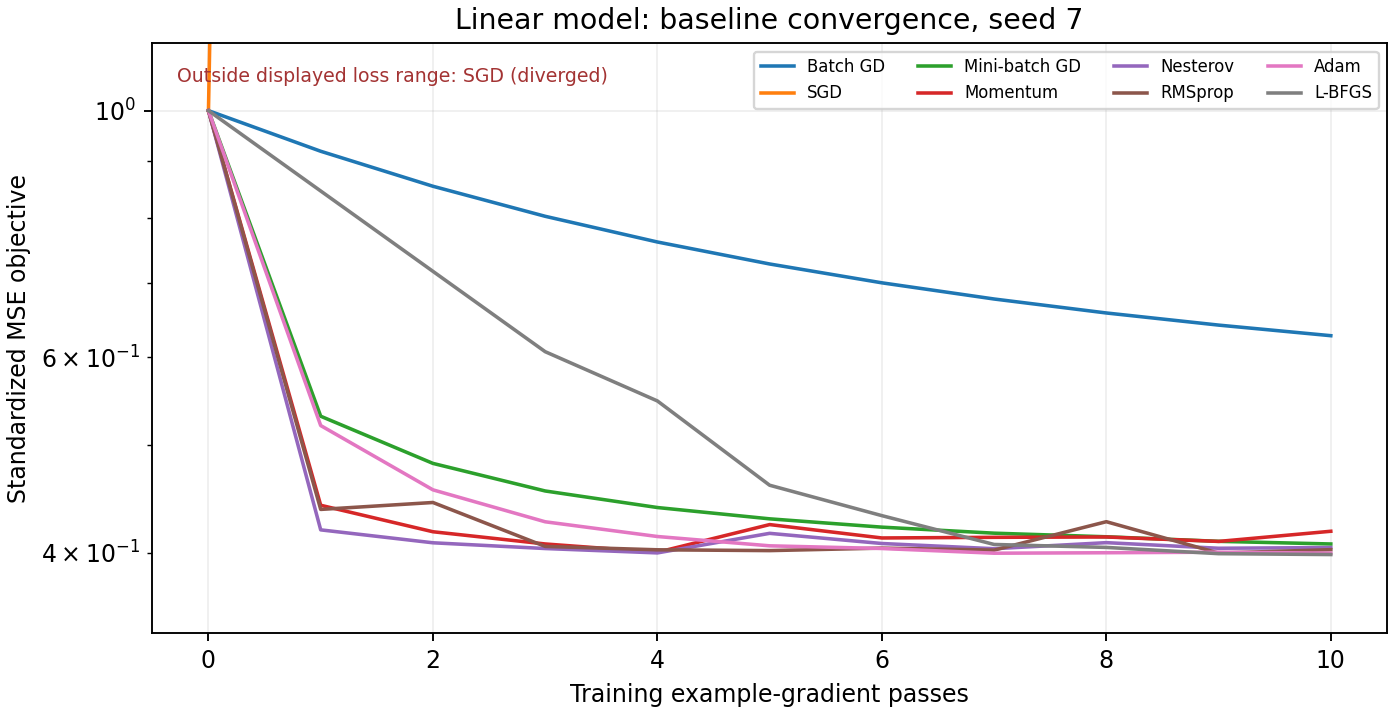

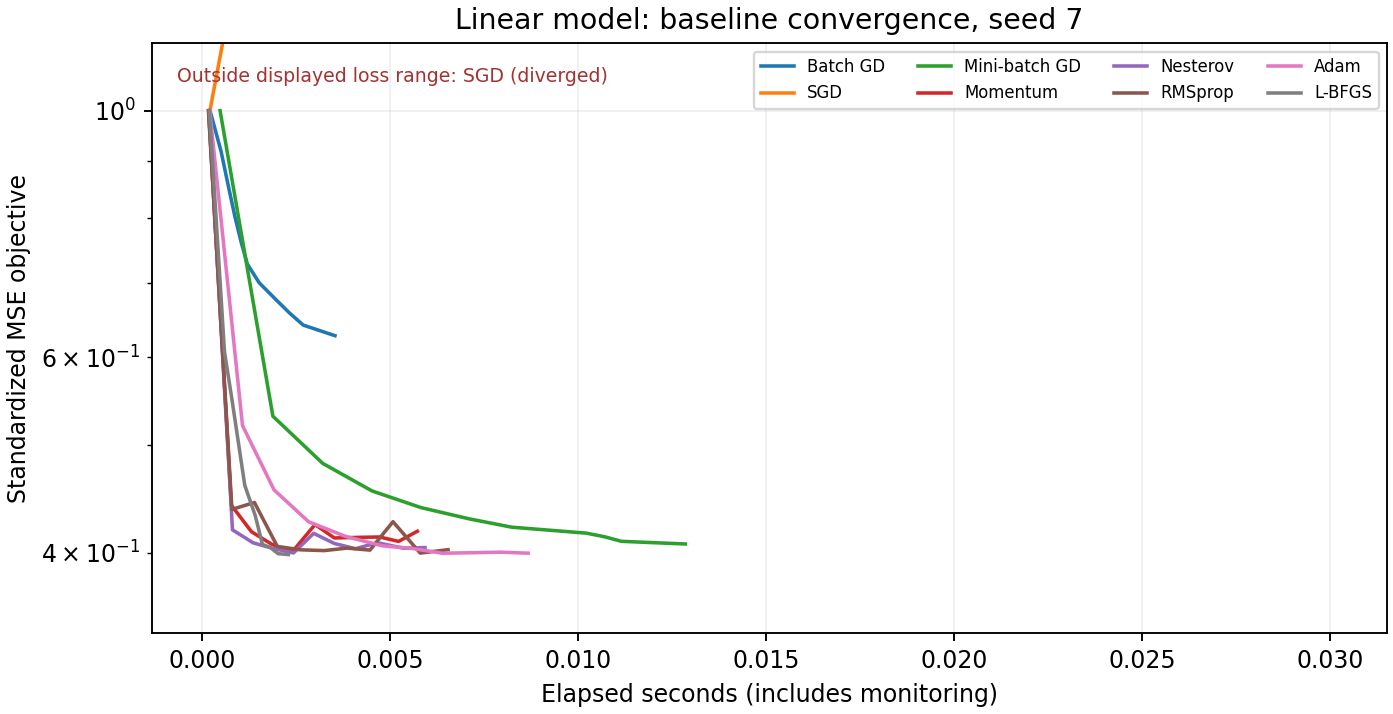

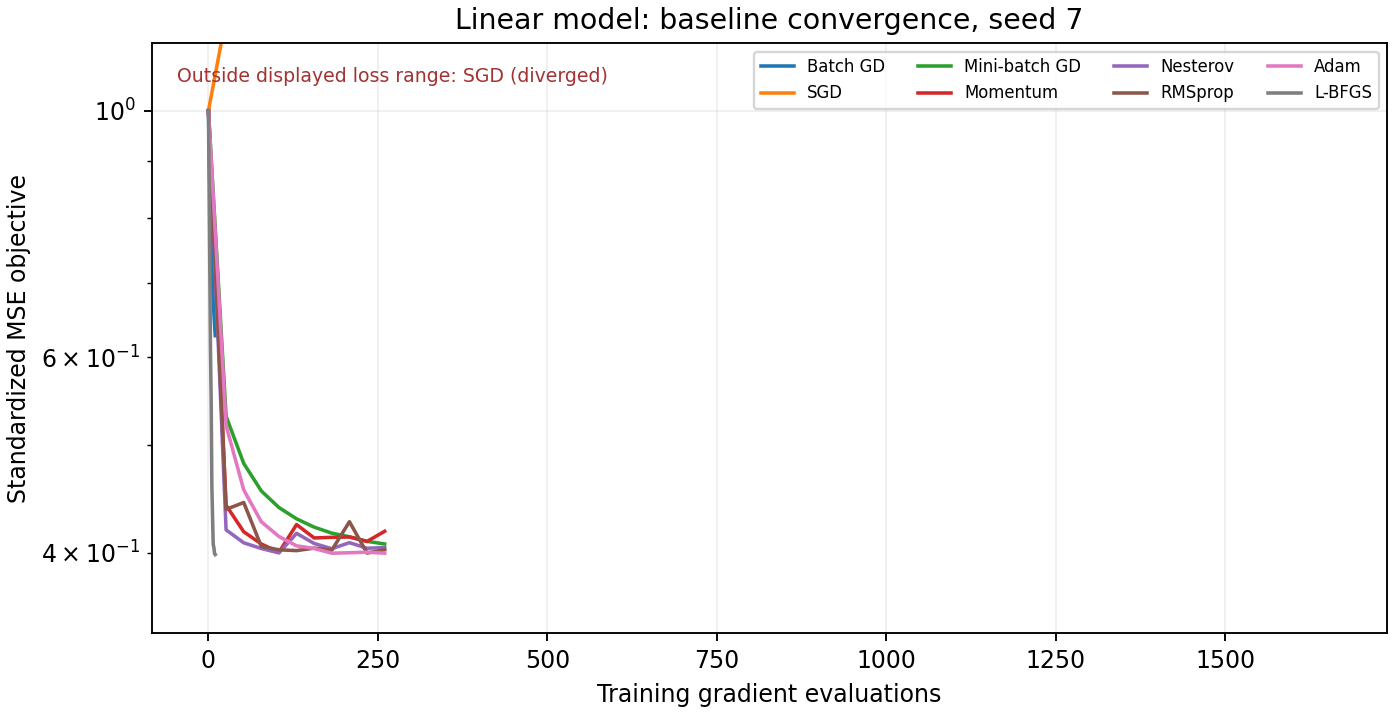

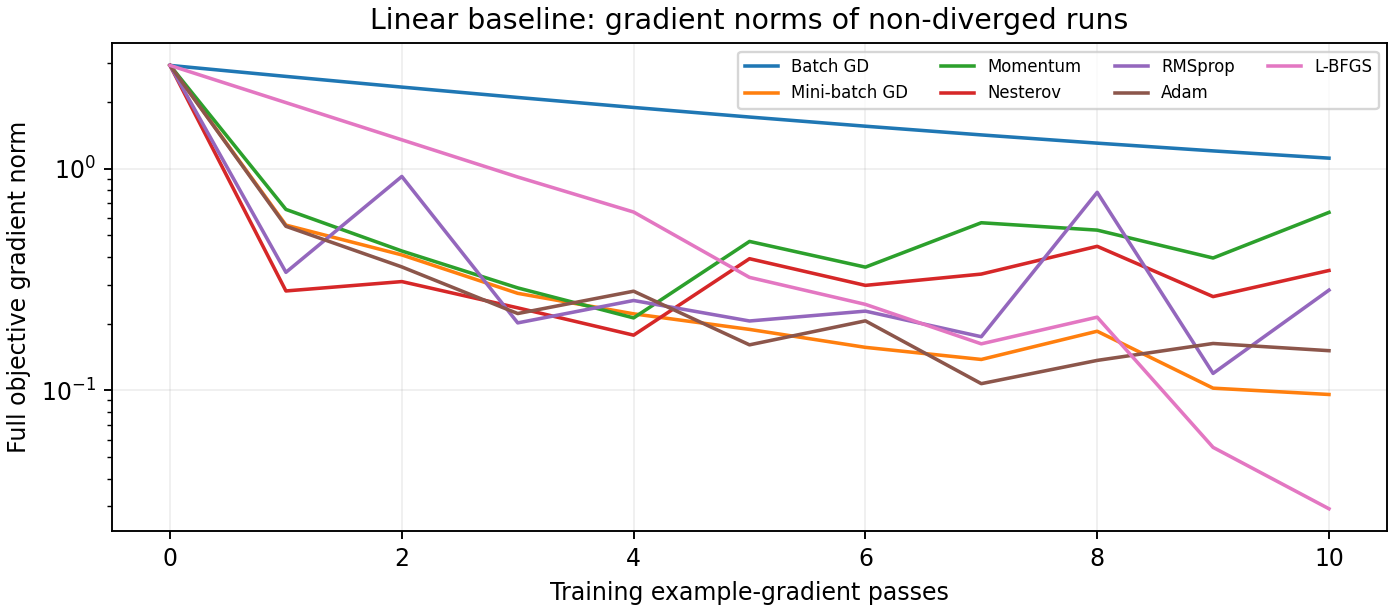

,optimizer,updates,gradient_evaluations,function_evaluations,monitor_gradient_evaluations,effective_passes,threshold_seconds,final_gradient_norm,loss_increase_fraction,peak_observed_process_rss_mib,status
0,Batch GD,10,10,10,11,10.000000,NaN,1.115217,0.0,702.542969,budget_completed
3,SGD,3219,3219,3219,2,1.943841,NaN,992.724161,1.0,702.558594,diverged
6,Mini-batch GD,260,260,260,11,10.000000,NaN,0.095794,0.0,702.558594,budget_completed
9,Momentum,260,260,260,11,10.000000,NaN,0.634857,0.4,702.558594,budget_completed
18,Nesterov,260,260,260,11,10.000000,NaN,0.347182,0.3,702.558594,budget_completed
21,RMSprop,260,260,260,11,10.000000,NaN,0.283120,0.4,702.562500,budget_completed
24,Adam,260,260,260,11,10.000000,NaN,0.150974,0.2,702.562500,budget_completed
63,L-BFGS,8,10,10,9,10.000000,NaN,0.029228,0.0,706.273438,budget_completed


In [22]:
for figure_name in ["convergence_effective_passes.png", "convergence_elapsed_seconds.png",
                    "convergence_gradient_evaluations.png", "gradient_norms.png"]:
    display(NotebookImage(filename=str(result_folder / "figures" / figure_name)))
baseline_counters = runs[(runs.model == "linear") & (runs.sweep == "baseline") & (runs.seed == 7)]
display(baseline_counters[["optimizer", "updates", "gradient_evaluations", "function_evaluations",
                           "monitor_gradient_evaluations", "effective_passes", "threshold_seconds",
                           "final_gradient_norm", "loss_increase_fraction", "peak_observed_process_rss_mib", "status"]])

## 20. One-factor sensitivity from the optimization lab

Each panel varies one parameter relative to its pairing's baseline; other parameters and the seeds stay fixed. Diverged repetitions have no eligible sensitivity score. The expanded full optimizer study remains opt-in and is not claimed by the default measurements.

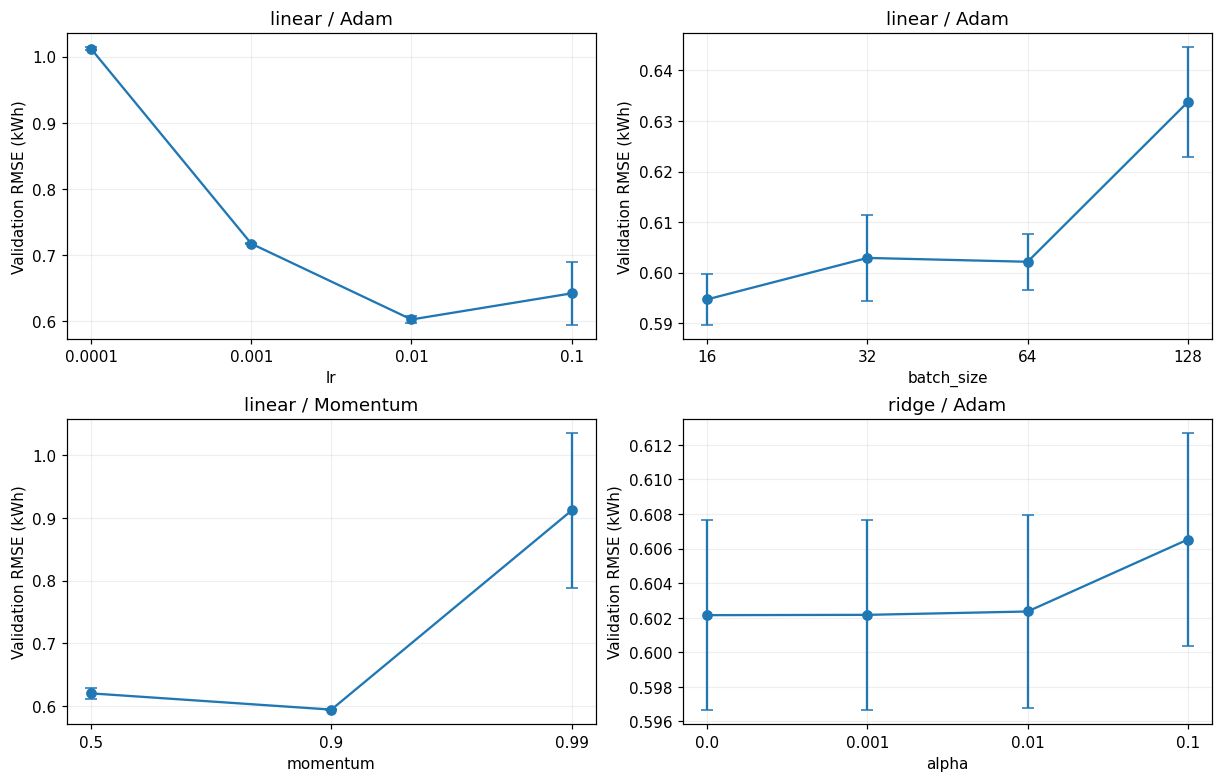

In [23]:
def lab_sensitivity(frame, family, method, parameter):
    subset = frame[(frame.model == family) & (frame.optimizer == method)].copy()
    baseline = subset[subset.sweep == "baseline"].iloc[0]
    for field in ["lr", "batch_size", "momentum", "alpha", "epochs", "scaling", "schedule"]:
        if field != parameter:
            subset = subset[subset[field] == baseline[field]]
    subset["eligible_score"] = subset.val_rmse.where(subset.status != "diverged")
    return subset.groupby(parameter).eligible_score.agg(["mean", "std", "count"]).reset_index()

figure, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
sensitivity_pairs = [("linear", "Adam", "lr"), ("linear", "Adam", "batch_size"),
                     ("linear", "Momentum", "momentum"), ("ridge", "Adam", "alpha")]
for axis, (family, method, parameter) in zip(axes.flat, sensitivity_pairs):
    sensitivity = lab_sensitivity(runs, family, method, parameter)
    axis.errorbar(np.arange(len(sensitivity)), sensitivity["mean"], yerr=sensitivity["std"].fillna(0), marker="o", capsize=4)
    axis.set_xticks(np.arange(len(sensitivity)), sensitivity[parameter].astype(str))
    axis.set(title=f"{family} / {method}", xlabel=parameter, ylabel="Validation RMSE (kWh)")
plt.show()

## 21. A stronger forecasting protocol

The second study covers the complete available chronology. It uses **calendar-duration boundaries**, rather than applying a row-count splitter to irregularly retained hourly records.

* First 80% of elapsed time is development. Three later outer validation windows run from 50% to 80% of the chronology. Last 20% is the final holdout.
* Each outer training set reserves its last 15% of rows as an **inner checkpoint period**. Scalers fit on the earlier fitting subset. Neural checkpoint selection never observes the outer validation window.
* A 24-hour embargo separates fitted labels/checkpoints/evaluation periods. Earlier observed hours inside a held-out period may support later one-step origins, as they would when issuing real one-step forecasts.
* Seasonal naive references predict the correct next-hour interval: at origin t, daily is $e_{t-23}$ and weekly is $e_{t-167}$, since the target is $e_{t+1}$.
* All model and naive comparisons use common observed target rows. Coverage loss is disclosed. This prevents scoring one method on an easier subset than another.
* Hyperparameters are selected by mean outer-fold RMSE; seed repetitions are averaged within folds first. Every required seed and fold must be eligible. The final selection is written to disk before final test errors are computed.

The boosted-tree reference disables its random internal early stopping. Direct ridge's library coefficient is mapped to the same stated MSE-plus-L2 convention. Different model families have different tuning resources; this forecasting benchmark must not be interpreted as a controlled comparison of update rules.

Method references: [scikit-learn's time-series forecasting example](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html), [time-series validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html), and [Forecasting: Principles and Practice](https://otexts.com/fpp3/toolbox.html).

In [24]:
"""Calendar-based temporal validation and a held-out forecasting benchmark.

This code is embedded as normal Python cells in the portfolio notebook. It uses
the notebook's tested PreparedData, train(), TrainConfig and metric functions.
"""
from dataclasses import dataclass, replace
from pathlib import Path
import hashlib
import json
import time

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits


@dataclass(frozen=True)
class PortfolioProtocol:
    folds: int = 3
    development_fraction: float = .80
    first_validation_fraction: float = .50
    embargo_hours: int = 24
    checkpoint_fraction: float = .15
    epochs: int = 20
    seeds: tuple = (7, 21, 42)
    bootstrap_repetitions: int = 1000
    train_row_cap: int | None = None
    evaluation_row_cap: int | None = None

    def validate(self):
        if self.folds < 2 or not 0 < self.first_validation_fraction < self.development_fraction < 1:
            raise ValueError("Require at least two folds and ordered split fractions")
        if not 0 < self.checkpoint_fraction < .5 or self.embargo_hours < 1:
            raise ValueError("Invalid checkpoint split or embargo")
        if self.epochs < 1 or not self.seeds or self.bootstrap_repetitions < 20:
            raise ValueError("Invalid training or resampling budget")
        return self


NAIVE_COLUMNS = {
    "Persistence": "naive_persistence",
    "Daily seasonal": "naive_daily",
    "Weekly seasonal": "naive_weekly",
    "Trailing 24h mean": "naive_rolling",
}


def portfolio_frame_from_hourly(hourly):
    frame = supervised_frame(hourly)
    raw = hourly.energy_kwh.asfreq("h")
    frame["naive_persistence"] = frame.energy_current
    # Forecast target is e_(t+1): daily seasonal = e_(t-23), weekly = e_(t-167).
    # Using shift(24)/shift(168) here would predict the wrong hourly interval.
    frame["naive_daily"] = raw.shift(23).reindex(frame.index)
    frame["naive_weekly"] = raw.shift(167).reindex(frame.index)
    frame["naive_rolling"] = frame.rolling_mean_24
    # All benchmark methods are compared on exactly the same observed targets.
    common = frame.dropna().copy()
    coverage = {"causal_supervised_rows": len(frame), "common_support_rows": len(common),
                "common_support_fraction": len(common)/len(frame),
                "filter": "all features, observed target, and daily/weekly baseline available"}
    return common, coverage


def calendar_splits(frame, protocol):
    protocol.validate()
    start, stop = frame.index.min(), frame.index.max() + pd.Timedelta(hours=1)
    duration = stop - start
    holdout_start = (start + protocol.development_fraction*duration).ceil("h")
    edges = [(start + f*duration).ceil("h") for f in np.linspace(
        protocol.first_validation_fraction, protocol.development_fraction, protocol.folds+1)]
    gap = pd.Timedelta(hours=protocol.embargo_hours)
    folds = []
    for i, (left, right) in enumerate(zip(edges[:-1], edges[1:]), 1):
        outer_train = frame.loc[frame.target_time < left-gap].copy()
        outer_validation = frame.loc[(frame.index >= left) & (frame.target_time < right)].copy()
        if protocol.train_row_cap:
            outer_train = outer_train.tail(protocol.train_row_cap)
        if protocol.evaluation_row_cap:
            outer_validation = outer_validation.tail(protocol.evaluation_row_cap)
        if len(outer_train) < 200 or len(outer_validation) < 48:
            raise ValueError("Insufficient rows in a calendar validation fold")
        folds.append((i, outer_train, outer_validation))
    development = frame.loc[frame.target_time < holdout_start-gap].copy()
    holdout = frame.loc[frame.index >= holdout_start].copy()
    if protocol.train_row_cap:
        development = development.tail(protocol.train_row_cap)
    if protocol.evaluation_row_cap:
        holdout = holdout.tail(protocol.evaluation_row_cap)
    if len(holdout) < 48:
        raise ValueError("Insufficient final holdout rows")
    return folds, development, holdout, holdout_start


def temporal_prepared_data(outer_train, evaluation, protocol, feature_names=None):
    """Reserve an INNER checkpoint period; the outer validation/test is never a checkpoint."""
    excluded = {"target", "target_time", *NAIVE_COLUMNS.values()}
    names = list(feature_names or [c for c in outer_train if c not in excluded])
    checkpoint_start = outer_train.index[int(len(outer_train)*(1-protocol.checkpoint_fraction))]
    checkpoint = outer_train.loc[outer_train.index >= checkpoint_start].copy()
    fitting = outer_train.loc[outer_train.target_time < checkpoint_start-pd.Timedelta(hours=protocol.embargo_hours)].copy()
    if len(fitting) < 100 or len(checkpoint) < 24:
        raise ValueError("Insufficient inner train/checkpoint rows")
    if fitting.target_time.max() >= checkpoint.index.min():
        raise AssertionError("Inner checkpoint leakage")
    if checkpoint.target_time.max() >= evaluation.index.min():
        raise AssertionError("Outer evaluation leakage")
    scaler = StandardScaler().fit(fitting[names].to_numpy(float))
    mean, std = float(fitting.target.mean()), max(float(fitting.target.std(ddof=0)), 1e-8)
    X = lambda frame: scaler.transform(frame[names].to_numpy(float))
    y = lambda frame: (frame.target.to_numpy(float)-mean)/std
    return PreparedData(X(fitting), X(checkpoint), X(evaluation), y(fitting), y(checkpoint), y(evaluation),
                        {"train": fitting, "validation": checkpoint, "test": evaluation}, names,
                        scaler, mean, std, "standard")


def benchmark_candidates(ci=False):
    candidates = [{"family": family, "kind": "naive", "column": column} for family, column in NAIVE_COLUMNS.items()]
    candidates += [{"family": "OLS", "kind": "ols"}]
    candidates += [{"family": "Ridge direct", "kind": "ridge", "alpha": alpha}
                   for alpha in ((.01,) if ci else (.0001, .001, .01, .1))]
    for kind, family in (("ridge_adam", "Ridge / Adam"), ("ann_adam", "ANN / Adam")):
        candidates += [{"family": family, "kind": kind, "lr": lr, "alpha": .01 if kind == "ridge_adam" else 0.}
                       for lr in ((.01,) if ci else (.001, .01))]
    candidates += [{"family": "Histogram boosting", "kind": "histogram", "lr": lr}
                   for lr in ((.05,) if ci else (.05, .1))]
    return candidates


def fit_benchmark_candidate(specification, prepared, protocol, seed):
    started = time.perf_counter()
    kind = specification["kind"]
    summary = {"status": "completed", "best_epoch": None, "processed_examples": None}
    if kind == "naive":
        model = None
    elif kind == "ols":
        model = LinearRegression().fit(prepared.X_train, prepared.y_train)
    elif kind == "ridge":
        # sklearn minimizes SSE+alpha_sklearn||w||^2. Match MSE+alpha/2||w||^2.
        mapped_alpha = len(prepared.y_train)*specification["alpha"]/2
        model = Ridge(alpha=mapped_alpha).fit(prepared.X_train, prepared.y_train)
    elif kind == "histogram":
        model = HistGradientBoostingRegressor(learning_rate=specification["lr"],
                    max_iter=20 if protocol.epochs <= 2 else 120, max_leaf_nodes=15,
                    min_samples_leaf=30, l2_regularization=.1,
                    early_stopping=False, random_state=seed).fit(prepared.X_train, prepared.y_train)
        # Disable sklearn's random internal validation; outer folds own evaluation.
    else:
        cfg = TrainConfig(model="ridge" if kind == "ridge_adam" else "ann", optimizer="Adam",
                          lr=specification["lr"], alpha=specification["alpha"], epochs=protocol.epochs,
                          batch_size=128, seed=seed)
        result = train(prepared, cfg)
        model = result.model
        summary = {key: result.summary[key] for key in ("status", "best_epoch", "processed_examples")}
    return model, {**summary, "fit_seconds": time.perf_counter()-started}


def benchmark_prediction(specification, model, prepared):
    if specification["kind"] == "naive":
        return prepared.frames["test"][specification["column"]].to_numpy(float)
    # Float64 export avoids pandas shortening float32 decimals differently from
    # the values used by the metric calculation; published scores then round-trip.
    return np.asarray(prepared.inverse_target(model.predict(prepared.X_test)), dtype=np.float64)


def forecast_portfolio(bundle, hourly, origin, horizon=1):
    if not 1 <= horizon <= 24:
        raise ValueError("Horizon must be between 1 and 24")
    origin = pd.Timestamp(origin)
    if origin not in hourly.index or origin < pd.Timestamp(bundle["metadata"]["holdout_first_origin"]):
        raise ValueError("Use a valid historical origin in or after the held-out period")
    history = hourly.loc[:origin, ["energy_kwh"]].copy()
    rows = []
    spec = bundle["specification"]
    for step in range(horizon):
        current = origin+pd.Timedelta(hours=step)
        features = features_at_origins(history).loc[[current]]
        if spec["kind"] == "naive":
            raw = history.energy_kwh.asfreq("h")
            estimates = {"naive_persistence": float(features.energy_current.iloc[0]),
                         "naive_rolling": float(features.rolling_mean_24.iloc[0]),
                         "naive_daily": raw.shift(23).loc[current], "naive_weekly": raw.shift(167).loc[current]}
            predicted = float(estimates[spec["column"]])
        else:
            X = features[bundle["feature_names"]].to_numpy(float)
            if not np.isfinite(X).all():
                raise ValueError("Insufficient finite history at this origin")
            X = bundle["scaler"].transform(X)
            predicted = float(bundle["model"].predict(X)[0]*bundle["y_std"]+bundle["y_mean"])
        if not np.isfinite(predicted):
            raise ValueError("Insufficient baseline history or non-finite forecast")
        target_time = current+pd.Timedelta(hours=1)
        rows.append({"origin": origin, "target_time": target_time, "horizon": step+1,
                     "predicted_kwh": predicted, "actual_kwh": hourly.energy_kwh.get(target_time, np.nan)})
        history.loc[target_time, "energy_kwh"] = predicted
    return pd.DataFrame(rows)


def moving_day_block_interval(target_times, actual, predicted, reference, block_days=7,
                              repetitions=1000, seed=2026):
    """Paired moving-calendar-day block bootstrap for delta RMSE, model minus reference.

    Daily SSE/count aggregation retains within-day error contributions. Empty
    calendar days stay in the grid. Overlapping blocks preserve local dependence;
    the percentile interval is approximate and assumes sufficient local stability.
    It is an interval on an aggregate metric difference, NOT a prediction interval.
    """
    arrays = [np.asarray(a, dtype=float) for a in (actual, predicted, reference)]
    actual, predicted, reference = arrays
    if len(actual) < 2 or any(len(a) != len(actual) for a in arrays) or not all(np.isfinite(a).all() for a in arrays):
        raise ValueError("Require equally sized finite paired arrays")
    if block_days < 1 or repetitions < 20:
        raise ValueError("Invalid bootstrap budget")
    dates = pd.DatetimeIndex(target_times)-pd.Timedelta(hours=1)
    if len(dates) != len(actual) or dates.isna().any() or dates.has_duplicates or not dates.is_monotonic_increasing:
        raise ValueError("Require unique, chronological valid target times matching the arrays")
    daily = pd.DataFrame({"model_sse": (actual-predicted)**2,
                          "reference_sse": (actual-reference)**2, "count": np.ones(len(actual))}, index=dates)
    daily = daily.resample("D").sum()
    days = len(daily)
    if days < block_days*2:
        raise ValueError("Holdout must contain at least two block lengths")
    values = daily.to_numpy()
    rng = np.random.default_rng(seed)
    bootstrap = np.empty(repetitions)
    blocks = int(np.ceil(days/block_days))
    offsets = np.arange(block_days)
    for i in range(repetitions):
        starts = rng.integers(0, days-block_days+1, size=blocks)
        indices = (starts[:, None]+offsets).ravel()[:days]
        sums = values[indices].sum(axis=0)
        if sums[2] == 0:
            bootstrap[i] = np.nan
        else:
            bootstrap[i] = np.sqrt(sums[0]/sums[2])-np.sqrt(sums[1]/sums[2])
    finite = bootstrap[np.isfinite(bootstrap)]
    if len(finite) < repetitions*.9:
        raise ValueError("Insufficient populated bootstrap samples")
    return {"delta_rmse": float(np.sqrt(np.mean((actual-predicted)**2))-np.sqrt(np.mean((actual-reference)**2))),
            "ci_low": float(np.quantile(finite, .025)), "ci_high": float(np.quantile(finite, .975)),
            "block_days": block_days, "repetitions": repetitions, "calendar_days": days}


def select_portfolio_candidates(cv, specifications, protocol):
    # First average seeds within a fold, then folds. Neither uses final test scores.
    fold_means = cv[cv.status != "diverged"].groupby(["family", "candidate_id", "fold"]).agg(
        validation_rmse=("validation_rmse", "mean"), seed_count=("seed", "nunique")).reset_index()
    required = {fingerprint(s): len(protocol.seeds) if s["kind"] in {"ridge_adam", "ann_adam"} else 1 for s in specifications}
    fold_means = fold_means[fold_means.apply(lambda row: row.seed_count == required[row.candidate_id], axis=1)]
    selection = fold_means.groupby(["family", "candidate_id"]).agg(
        cv_rmse_mean=("validation_rmse", "mean"), cv_rmse_fold_sd=("validation_rmse", "std"),
        eligible_folds=("fold", "nunique")).reset_index()
    selection = selection[selection.eligible_folds == protocol.folds]
    return selection.sort_values(["cv_rmse_mean", "candidate_id"]).groupby("family", sort=False).head(1)


def run_portfolio_benchmark(hourly, protocol, output, ci=False):
    protocol.validate()
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    frame, coverage = portfolio_frame_from_hourly(hourly)
    folds, development, holdout, cutoff = calendar_splits(frame, protocol)
    protocol_hash = fingerprint({"protocol": protocol.__dict__, "ci": ci,
        "hourly_hash": hashlib.sha256(pd.util.hash_pandas_object(hourly, index=True).values.tobytes()).hexdigest(),
        "benchmark_version": "2.0.0", "environment": environment()})
    fold_rows = []
    for fold_id, training_frame, validation_frame in folds:
        prepared = temporal_prepared_data(training_frame, validation_frame, protocol)
        fold_rows.append({"fold": fold_id, "train_start": str(prepared.frames["train"].index.min()),
                          "train_end_target": str(prepared.frames["train"].target_time.max()),
                          "checkpoint_start": str(prepared.frames["validation"].index.min()),
                          "checkpoint_end_target": str(prepared.frames["validation"].target_time.max()),
                          "outer_validation_start": str(validation_frame.index.min()),
                          "outer_validation_end_target": str(validation_frame.target_time.max()),
                          "fit_rows": len(prepared.y_train), "checkpoint_rows": len(prepared.y_val),
                          "outer_validation_rows": len(prepared.y_test)})
    pd.DataFrame(fold_rows).to_csv(output / "temporal_folds.csv", index=False)
    # The protocol and all candidates are frozen on disk BEFORE any outer scores.
    specifications = benchmark_candidates(ci)
    write_json(output / "protocol.json", {"protocol_hash": protocol_hash, "profile": "ci" if ci else "portfolio",
        "protocol": protocol.__dict__, "coverage": coverage, "candidates": specifications,
        "holdout_start": str(holdout.index.min()), "holdout_end_target": str(holdout.target_time.max()),
        "holdout_rows": len(holdout), "embargo_cutoff": str(cutoff), "environment": environment(),
        "selection": "mean outer validation RMSE over three calendar folds and seeds; inner checkpoint selection is separate",
        "note": "Calendar windows are fixed by elapsed time, not by row counts; missing observations remain missing."})
    cv_rows, ablation_rows = [], []
    for fold_id, training_frame, validation_frame in folds:
        prepared = temporal_prepared_data(training_frame, validation_frame, protocol)
        for spec in specifications:
            spec_id = fingerprint(spec)
            seeds = protocol.seeds if spec["kind"] in {"ridge_adam", "ann_adam"} else (protocol.seeds[0],)
            for seed in seeds:
                model, info = fit_benchmark_candidate(spec, prepared, protocol, seed)
                prediction = benchmark_prediction(spec, model, prepared)
                metrics = regression_metrics(validation_frame.target.to_numpy(), prediction)
                cv_rows.append({"fold": fold_id, "candidate_id": spec_id, "family": spec["family"],
                                "seed": seed, "specification": json.dumps(spec, sort_keys=True), **info,
                                **{"validation_"+key: value for key, value in metrics.items()}})
        # Fixed-alpha ablations use exactly the same target rows and calendar folds.
        all_names = prepared.feature_names
        history_names = [n for n in all_names if n.startswith(("energy_", "lag_", "rolling_")) or n == "current_missing"]
        calendar_names = [n for n in all_names if n not in history_names]
        for label, names in (("All features", all_names), ("History only", history_names), ("Calendar only", calendar_names)):
            ablated = temporal_prepared_data(training_frame, validation_frame, protocol, names)
            specification = {"family": "Ablation", "kind": "ridge", "alpha": .01}
            model, _ = fit_benchmark_candidate(specification, ablated, protocol, protocol.seeds[0])
            score = regression_metrics(validation_frame.target, benchmark_prediction(specification, model, ablated))
            ablation_rows.append({"fold": fold_id, "feature_group": label, "features": len(names), **score})
        print(f"Calendar validation fold {fold_id}/{protocol.folds} completed", flush=True)
    cv = pd.DataFrame(cv_rows)
    cv.to_csv(output / "cross_validation_runs.csv", index=False)
    pd.DataFrame(ablation_rows).to_csv(output / "feature_ablation.csv", index=False)
    selected = select_portfolio_candidates(cv, specifications, protocol)
    selected.to_csv(output / "selected_candidates.csv", index=False)
    # Freeze selection before revealing any final holdout error.
    champion_family = str(selected.iloc[0].family)
    selected_naive = str(selected[selected.family.isin(NAIVE_COLUMNS)].iloc[0].family)
    write_json(output / "frozen_selection.json", {"champion_family": champion_family,
        "naive_reference_family": selected_naive, "deployment_seed": protocol.seeds[0],
        "candidate_ids": selected.set_index("family").candidate_id.to_dict(), "protocol_hash": protocol_hash})
    final_prepared = temporal_prepared_data(development, holdout, protocol)
    predictions = holdout[["target_time", "target"]].rename(columns={"target": "actual_kwh"}).reset_index()
    final_rows, deployed = [], {}
    lookup = {fingerprint(spec): spec for spec in specifications}
    for _, selected_row in selected.iterrows():
        spec = lookup[selected_row.candidate_id]
        seeds = protocol.seeds if spec["kind"] in {"ridge_adam", "ann_adam"} else (protocol.seeds[0],)
        for seed in seeds:
            model, info = fit_benchmark_candidate(spec, final_prepared, protocol, seed)
            prediction = benchmark_prediction(spec, model, final_prepared)
            score = regression_metrics(holdout.target, prediction)
            final_rows.append({"family": spec["family"], "candidate_id": selected_row.candidate_id,
                               "seed": seed, **info, **{"test_"+key: value for key, value in score.items()}})
            predictions[f"{spec['family']} / seed {seed}"] = prediction
            if seed == protocol.seeds[0]:
                predictions[spec["family"]] = prediction
                deployed[spec["family"]] = {"model": model, "specification": spec,
                    "scaler": final_prepared.scaler, "feature_names": final_prepared.feature_names,
                    "y_mean": final_prepared.y_mean, "y_std": final_prepared.y_std,
                    "metadata": {"protocol_hash": protocol_hash, "fitting_last_target": str(final_prepared.frames["train"].target_time.max()),
                                 "checkpoint_last_target": str(final_prepared.frames["validation"].target_time.max()),
                                 "holdout_first_origin": str(holdout.index.min()), "selection": "outer validation only"}}
    final_runs = pd.DataFrame(final_rows)
    final_runs.to_csv(output / "holdout_runs.csv", index=False)
    board = final_runs.groupby("family").agg(test_rmse_mean=("test_rmse", "mean"),
        test_rmse_seed_sd=("test_rmse", "std"), test_mae_mean=("test_mae", "mean"),
        test_r2_mean=("test_r2", "mean"), fit_seconds_mean=("fit_seconds", "mean"),
        final_seed_count=("seed", "nunique")).reset_index()
    board = selected.merge(board, on="family").sort_values("cv_rmse_mean")
    board.to_csv(output / "forecasting_leaderboard.csv", index=False)
    predictions.to_csv(output / "holdout_predictions.csv", index=False)
    joblib.dump(deployed[champion_family], output / "trusted_champion.joblib")
    intervals = []
    for block_days in (1, 7, 14):
        intervals.append({"model": champion_family, "reference": selected_naive,
            **moving_day_block_interval(predictions.target_time, predictions.actual_kwh,
                                       predictions[champion_family], predictions[selected_naive],
                                       block_days=block_days, repetitions=protocol.bootstrap_repetitions)})
    pd.DataFrame(intervals).to_csv(output / "paired_block_bootstrap.csv", index=False)
    diagnostics = pd.DataFrame({"origin": predictions.origin, "target_time": predictions.target_time,
        "actual": predictions.actual_kwh, "prediction": predictions[champion_family],
        "residual": predictions.actual_kwh-predictions[champion_family]})
    diagnostics["month"] = diagnostics.origin.dt.to_period("M").astype(str)
    diagnostics["hour"] = diagnostics.origin.dt.hour
    diagnostics["weekday"] = diagnostics.origin.dt.dayofweek
    slices = []
    for dimension in ("month", "hour", "weekday"):
        for label, group in diagnostics.groupby(dimension):
            slices.append({"dimension": dimension, "slice": str(label), "rows": len(group),
                           **regression_metrics(group.actual, group.prediction)})
    pd.DataFrame(slices).to_csv(output / "error_slices.csv", index=False)
    write_json(output / "summary.json", {"champion_family": champion_family, "reference_family": selected_naive,
        "deployment_seed": protocol.seeds[0], "holdout_rows": len(holdout), "coverage": coverage,
        "candidate_repetitions": len(cv), "final_repetitions": len(final_runs), "ablations": len(ablation_rows),
        "protocol_hash": protocol_hash, "tests_are_one_step": True,
        "negative_deployment_forecasts": int((predictions[champion_family] < 0).sum())})
    return board, predictions, pd.DataFrame(intervals)

## 22. Additional scientific verification

These tests specifically check seasonal alignment, inner/outer separation, embargoes, objective conventions, incomplete-seed exclusion, recursive causality and paired-bootstrap behavior. Their small synthetic fixture is used only for correctness testing.

In [25]:
"""Additional notebook tests for the temporal evaluation and uncertainty methods."""
import unittest


class PortfolioScientificTests(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        index = pd.date_range("2018-01-01", periods=4000, freq="h", name="origin")
        values = 1.2+.4*np.sin(np.arange(len(index))*2*np.pi/24)+.00005*np.arange(len(index))
        cls.hourly = pd.DataFrame({"energy_kwh": values, "observed_minutes": 60}, index=index)
        cls.frame, _ = portfolio_frame_from_hourly(cls.hourly)
        cls.protocol = PortfolioProtocol(epochs=2, bootstrap_repetitions=40)

    def test_next_hour_seasonal_alignment(self):
        origin = self.hourly.index[500]
        row = self.frame.loc[origin]
        self.assertEqual(row.naive_daily, self.hourly.energy_kwh.loc[origin-pd.Timedelta(hours=23)])
        self.assertEqual(row.naive_weekly, self.hourly.energy_kwh.loc[origin-pd.Timedelta(hours=167)])
        self.assertEqual(row.target, self.hourly.energy_kwh.loc[origin+pd.Timedelta(hours=1)])

    def test_baseline_inputs_ignore_future_values(self):
        origin = self.hourly.index[2000]
        altered = self.hourly.copy()
        altered.loc[altered.index > origin, "energy_kwh"] = 9999
        changed, _ = portfolio_frame_from_hourly(altered)
        columns = list(NAIVE_COLUMNS.values())
        pd.testing.assert_frame_equal(self.frame.loc[:origin, columns], changed.loc[:origin, columns])

    def test_embargo_and_holdout_separation(self):
        folds, development, holdout, cutoff = calendar_splits(self.frame, self.protocol)
        gap = pd.Timedelta(hours=self.protocol.embargo_hours)
        for _, fitting, validation in folds:
            self.assertLess(fitting.target_time.max(), validation.index.min()-gap)
            self.assertLess(validation.target_time.max(), cutoff)
        self.assertLess(development.target_time.max(), holdout.index.min()-gap)

    def test_inner_checkpoint_is_distinct_from_outer_validation(self):
        folds, _, _, _ = calendar_splits(self.frame, self.protocol)
        _, training, validation = folds[0]
        prepared = temporal_prepared_data(training, validation, self.protocol)
        self.assertLess(prepared.frames["train"].target_time.max(), prepared.frames["validation"].index.min())
        self.assertLess(prepared.frames["validation"].target_time.max(), prepared.frames["test"].index.min())
        np.testing.assert_allclose(prepared.scaler.mean_, prepared.frames["train"][prepared.feature_names].mean())

    def test_outer_targets_never_change_fitted_transforms(self):
        folds, _, _, _ = calendar_splits(self.frame, self.protocol)
        _, training, validation = folds[0]
        prepared = temporal_prepared_data(training, validation, self.protocol)
        changed = validation.copy()
        changed["target"] = 9999
        second = temporal_prepared_data(training, changed, self.protocol)
        np.testing.assert_array_equal(prepared.X_train, second.X_train)
        self.assertEqual(prepared.y_mean, second.y_mean)
        self.assertEqual(prepared.y_std, second.y_std)

    def test_direct_ridge_matches_stated_objective(self):
        folds, _, _, _ = calendar_splits(self.frame, self.protocol)
        _, training, validation = folds[0]
        prepared = temporal_prepared_data(training, validation, self.protocol)
        spec = {"family": "ridge", "kind": "ridge", "alpha": .01}
        with threadpool_limits(limits=1):
            model, _ = fit_benchmark_candidate(spec, prepared, self.protocol, 7)
        w = np.r_[model.coef_, model.intercept_]
        _, gradient = linear_objective(w, LinearModel.design(prepared.X_train), prepared.y_train, .01)
        self.assertLess(np.linalg.norm(gradient), 1e-8)

    def test_all_benchmark_families_fit(self):
        folds, _, _, _ = calendar_splits(self.frame, self.protocol)
        _, training, validation = folds[0]
        prepared = temporal_prepared_data(training, validation, self.protocol)
        with threadpool_limits(limits=1):
            for spec in benchmark_candidates(ci=True):
                with self.subTest(family=spec["family"]):
                    model, _ = fit_benchmark_candidate(spec, prepared, self.protocol, 7)
                    prediction = benchmark_prediction(spec, model, prepared)
                    self.assertTrue(np.isfinite(prediction).all())
                    self.assertEqual(len(prediction), len(validation))

    def test_bootstrap_identical_predictors_have_zero_difference(self):
        actual = self.frame.target.to_numpy()
        predicted = self.frame.naive_persistence.to_numpy()
        interval = moving_day_block_interval(self.frame.target_time, actual, predicted, predicted,
                                             block_days=7, repetitions=40)
        self.assertEqual(interval["delta_rmse"], 0)
        self.assertEqual(interval["ci_low"], 0)
        self.assertEqual(interval["ci_high"], 0)

    def test_bootstrap_is_seed_reproducible(self):
        args = (self.frame.target_time, self.frame.target.to_numpy(), self.frame.naive_persistence.to_numpy(),
                self.frame.naive_daily.to_numpy())
        first = moving_day_block_interval(*args, repetitions=40, seed=7)
        second = moving_day_block_interval(*args, repetitions=40, seed=7)
        self.assertEqual(first, second)

    def test_bootstrap_rejects_invalid_alignment(self):
        with self.assertRaises(ValueError):
            moving_day_block_interval(self.frame.target_time.iloc[:10], [1, 2], [1, 2], [1, 2], repetitions=40)

    def test_incomplete_seed_or_fold_is_ineligible(self):
        first = {"family": "Candidate family", "kind": "ridge_adam", "lr": .001, "alpha": .01}
        second = {**first, "lr": .01}
        rows = []
        for spec in (first, second):
            for fold in range(1, self.protocol.folds+1):
                for seed in self.protocol.seeds:
                    failed = spec == first and fold == 1 and seed == 21
                    rows.append({"family": spec["family"], "candidate_id": fingerprint(spec), "fold": fold,
                                 "seed": seed, "status": "diverged" if failed else "completed",
                                 "validation_rmse": .1 if spec == first else .8})
        selected = select_portfolio_candidates(pd.DataFrame(rows), [first, second], self.protocol)
        self.assertEqual(selected.iloc[0].candidate_id, fingerprint(second))

    def test_portfolio_recursive_forecast_ignores_future(self):
        folds, _, _, _ = calendar_splits(self.frame, self.protocol)
        _, training, validation = folds[0]
        prepared = temporal_prepared_data(training, validation, self.protocol)
        spec = {"family": "Ridge", "kind": "ridge", "alpha": .01}
        model, _ = fit_benchmark_candidate(spec, prepared, self.protocol, 7)
        bundle = {"model": model, "specification": spec, "feature_names": prepared.feature_names,
                  "scaler": prepared.scaler, "y_mean": prepared.y_mean, "y_std": prepared.y_std,
                  "metadata": {"holdout_first_origin": str(validation.index.min())}}
        origin = validation.index[0]
        first = forecast_portfolio(bundle, self.hourly, origin, 24)
        changed = self.hourly.copy()
        changed.loc[changed.index > origin, "energy_kwh"] = 9999
        second = forecast_portfolio(bundle, changed, origin, 24)
        np.testing.assert_array_equal(first.predicted_kwh, second.predicted_kwh)


portfolio_test_suite = unittest.defaultTestLoader.loadTestsFromTestCase(PortfolioScientificTests)
portfolio_test_result = unittest.TextTestRunner(verbosity=1).run(portfolio_test_suite)
assert portfolio_test_result.wasSuccessful(), "Fix temporal evaluation tests before running the benchmark."

.

.

.

.

.

.

... (3 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 12 tests in 0.601s

OK


## 23. Execute the later-period benchmark

The protocol, candidate grid, data coverage, runtime and split boundaries are exported before model scores. Default runs use all available chronology, three outer folds, and three seeds for stochastic models. CPU BLAS and PyTorch use one thread during this comparison. CI caps are explicitly recorded and are not research results.

In [26]:
portfolio_protocol = PortfolioProtocol()
if PROFILE == "ci":
    portfolio_protocol = replace(portfolio_protocol, folds=2, epochs=2, seeds=(7,),
                                 bootstrap_repetitions=40, train_row_cap=2000, evaluation_row_cap=960)
portfolio_output = RESULTS / "temporal_benchmark"
with threadpool_limits(limits=1):
    forecasting_board, forecasting_predictions, uncertainty = run_portfolio_benchmark(
        hourly, portfolio_protocol, portfolio_output, ci=PROFILE == "ci")
display(pd.read_csv(portfolio_output / "temporal_folds.csv"))
display(forecasting_board.round(5))
display(uncertainty.round(5))

Calendar validation fold 1/3 completed


Calendar validation fold 2/3 completed


Calendar validation fold 3/3 completed


,fold,train_start,train_end_target,checkpoint_start,checkpoint_end_target,outer_validation_start,outer_validation_end_target,fit_rows,checkpoint_rows,outer_validation_rows
0,1,2006-12-23 18:00:00,2008-08-23 06:00:00,2008-08-24 07:00:00,2008-12-08 19:00:00,2008-12-09 20:00:00,2009-05-02 05:00:00,14354,2538,3408
1,2,2006-12-23 18:00:00,2008-12-23 02:00:00,2008-12-24 03:00:00,2009-05-01 05:00:00,2009-05-02 06:00:00,2009-09-22 15:00:00,17252,3049,3237
2,3,2006-12-23 18:00:00,2009-04-17 18:00:00,2009-04-18 19:00:00,2009-09-21 15:00:00,2009-09-22 16:00:00,2010-02-13 01:00:00,20004,3535,3288


,family,candidate_id,cv_rmse_mean,cv_rmse_fold_sd,eligible_folds,test_rmse_mean,test_rmse_seed_sd,test_mae_mean,test_r2_mean,fit_seconds_mean,final_seed_count
0,Histogram boosting,cf90cf021281bc57,0.52225,0.07841,3,0.47376,NaN,0.32957,0.58335,0.33880,1
1,ANN / Adam,79864b9bdf61b588,0.53902,0.07839,3,0.49375,0.00809,0.34483,0.54737,3.34519,3
2,Ridge direct,f5b7fd1f27fbf8ed,0.58106,0.08787,3,0.52702,NaN,0.37552,0.48441,0.00385,1
3,OLS,00366e1a61c13347,0.58130,0.08774,3,0.52732,NaN,0.37554,0.48382,0.00747,1
4,Ridge / Adam,46d02d4f1c2efb6f,0.58131,0.08838,3,0.52728,0.00108,0.37659,0.48390,0.16818,3
5,Persistence,a3c79ac3c40a4af5,0.66232,0.09552,3,0.59951,NaN,0.39332,0.33281,0.00000,1
6,Trailing 24h mean,126bdfaf3f7863ba,0.81489,0.16430,3,0.70409,NaN,0.55428,0.07976,0.00000,1
7,Weekly seasonal,63fa5c412a00d3f5,0.85368,0.14373,3,0.81552,NaN,0.56312,-0.23458,0.00000,1
8,Daily seasonal,b1b41d55f3bf39c6,0.90536,0.17147,3,0.78298,NaN,0.52742,-0.13802,0.00000,1


,model,reference,delta_rmse,ci_low,ci_high,block_days,repetitions,calendar_days
0,Histogram boosting,Persistence,-0.12575,-0.13787,-0.11367,1,1000,287
1,Histogram boosting,Persistence,-0.12575,-0.14122,-0.10593,7,1000,287
2,Histogram boosting,Persistence,-0.12575,-0.14130,-0.10187,14,1000,287


## 24. Results, ablations and diagnostic figures

Fold SD quantifies variation between temporal validation periods. Seed SD quantifies stochastic repetitions of a selected configuration; deterministic references have no estimated seed SD. The paired bootstrap concerns the fixed deployment seed 7 and a naive reference selected on validation, not whichever naive method happened to score best on test.

In [27]:
"""Static figures and evidence cards for notebook/GitHub review."""
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def portfolio_figures(output):
    output = Path(output)
    figures = output / "figures"
    figures.mkdir(exist_ok=True)
    board = pd.read_csv(output / "forecasting_leaderboard.csv")
    ablation = pd.read_csv(output / "feature_ablation.csv")
    errors = pd.read_csv(output / "error_slices.csv")
    intervals = pd.read_csv(output / "paired_block_bootstrap.csv")
    summary = json.loads((output / "summary.json").read_text())
    predictions = pd.read_csv(output / "holdout_predictions.csv", parse_dates=["origin", "target_time"])
    color, reference_color = "#127f82", "#d9973a"
    with plt.rc_context({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.titleweight": "bold", "grid.alpha": .15}):
        figure, axes = plt.subplots(2, 2, figsize=(13, 8.5), layout="constrained")
        colors = [reference_color if family in NAIVE_COLUMNS else color for family in board.family]
        axes[0, 0].barh(board.family, board.cv_rmse_mean, xerr=board.cv_rmse_fold_sd, color=colors, capsize=3)
        axes[0, 0].invert_yaxis()
        axes[0, 0].set(xlabel="Outer validation RMSE (kWh), mean +/- fold SD", title="01  Selection evidence")
        axes[0, 1].barh(board.family, board.test_rmse_mean, xerr=board.test_rmse_seed_sd.fillna(0), color=colors, capsize=3)
        axes[0, 1].invert_yaxis()
        axes[0, 1].set(xlabel="Final holdout RMSE (kWh), mean +/- seed SD", title="02  Later-period evaluation")
        ablation_summary = ablation.groupby("feature_group").rmse.agg(["mean", "std"]).sort_values("mean")
        axes[1, 0].bar(ablation_summary.index, ablation_summary["mean"], yerr=ablation_summary["std"], capsize=4,
                       color=[color, "#50979a", "#93b4bc"])
        axes[1, 0].set(ylabel="Outer validation RMSE (kWh)", title="03  Fixed-alpha ridge ablation")
        months = errors[errors.dimension == "month"]
        axes[1, 1].plot(months["slice"], months.mae, marker="o", color=color)
        axes[1, 1].tick_params(axis="x", rotation=40)
        axes[1, 1].set(ylabel="Final seed-7 champion MAE (kWh)", title="04  Error by held-out month")
        figure.suptitle("OptiEnergy AI | Optimization rigor meets temporal forecasting", fontsize=16, fontweight="bold")
        figure.savefig(figures / "portfolio_overview.png", dpi=170)
        plt.close(figure)

        figure, axes = plt.subplots(1, 3, figsize=(13, 3.9), layout="constrained")
        for _, interval in intervals.iterrows():
            low, high = interval.ci_low, interval.ci_high
            axes[0].plot([low, high], [interval.block_days, interval.block_days], lw=3, color=color)
            axes[0].scatter([interval.delta_rmse], [interval.block_days], color=reference_color, zorder=3)
        axes[0].axvline(0, color="black", linestyle="--", lw=1)
        axes[0].set(xlabel="Delta RMSE (kWh): champion minus CV-selected naive",
                    ylabel="Bootstrap block length (calendar days)", title="Paired 95% percentile intervals")
        residual = pd.Series(predictions.actual_kwh-predictions[summary["champion_family"]],
                             index=predictions.index)
        axes[1].scatter(predictions[summary["champion_family"]], residual, s=4, alpha=.3, color=color)
        axes[1].axhline(0, color="black", lw=1)
        axes[1].set(xlabel="Forecast (kWh)", ylabel="Actual - forecast (kWh)", title="Held-out residuals")
        residual_clock = pd.Series(residual.to_numpy(), index=predictions.origin).asfreq("h")
        lags = np.arange(1, 49)
        autocorrelation = [residual_clock.autocorr(lag=int(lag)) for lag in lags]
        axes[2].bar(lags, autocorrelation, color=color)
        axes[2].set(xlabel="Clock-hour lag", ylabel="Residual correlation", title="Remaining temporal dependence")
        figure.savefig(figures / "uncertainty_and_residuals.png", dpi=170)
        plt.close(figure)

        figure, axis = plt.subplots(figsize=(12, 3.7), layout="constrained")
        view = predictions.iloc[:168]
        axis.plot(view.target_time, view.actual_kwh, label="Observed", color="#1e2d43", lw=1.4)
        axis.plot(view.target_time, view[summary["champion_family"]], label=f"{summary['champion_family']} (seed 7)", color=color, lw=1.2)
        axis.set(xlabel="Target interval endpoint", ylabel="Hourly energy (kWh)", title="First held-out week: one-step forecasts")
        axis.legend(ncol=2, frameon=False)
        figure.savefig(figures / "heldout_forecasts.png", dpi=170)
        plt.close(figure)


def evidence_cards(output, dataset_metadata, core_test_count, scientific_test_count):
    output = Path(output)
    summary = json.loads((output / "summary.json").read_text())
    protocol = json.loads((output / "protocol.json").read_text())
    board = pd.read_csv(output / "forecasting_leaderboard.csv")
    intervals = pd.read_csv(output / "paired_block_bootstrap.csv")
    cv_selected = board.iloc[0]
    daily_interval = intervals[intervals.block_days == 7].iloc[0]
    naive_row = board[board.family == summary["reference_family"]].iloc[0]
    improvement = 100*(1-cv_selected.test_rmse_mean/naive_row.test_rmse_mean)
    rows = ["| Family | CV RMSE | CV fold SD | Holdout RMSE | Seed SD | Holdout MAE | Seeds |",
            "|---|---:|---:|---:|---:|---:|---:|"]
    for _, row in board.iterrows():
        seed_sd = f"{row.test_rmse_seed_sd:.4f}" if row.final_seed_count > 1 else "deterministic"
        rows.append(f"| {row.family} | {row.cv_rmse_mean:.4f} | {row.cv_rmse_fold_sd:.4f} | {row.test_rmse_mean:.4f} | {seed_sd} | {row.test_mae_mean:.4f} | {int(row.final_seed_count)} |")
    findings = f"""# Measured portfolio findings

The validation-selected forecasting family is **{summary['champion_family']}**. Its final holdout RMSE is **{cv_selected.test_rmse_mean:.4f} kWh**, averaged across its declared seeds. The strongest naive reference selected on cross-validation is **{summary['reference_family']}**, with holdout RMSE **{naive_row.test_rmse_mean:.4f} kWh**. The relative change is **{improvement:.2f}% lower RMSE** (negative values would mean worse performance).

The final holdout covers **{protocol['holdout_start']} through {protocol['holdout_end_target']}**, with **{summary['holdout_rows']:,}** common-support observations. Selection was frozen before final scoring. No family is chosen by the test leaderboard.

{chr(10).join(rows)}

## Uncertainty is a separate question

For the fixed deployment seed 7, delta RMSE against the cross-validation-selected naive reference is **{daily_interval.delta_rmse:.4f} kWh**. A paired seven-calendar-day moving-block bootstrap gives an approximate 95% percentile interval **[{daily_interval.ci_low:.4f}, {daily_interval.ci_high:.4f}] kWh**. Negative differences favor the champion. One- and fourteen-day intervals are exported to disclose block-length sensitivity. This is an interval on an aggregate metric difference, not an individual forecast interval, and does not include training-data uncertainty. Stationarity assumptions and one-household sampling limit interpretation.

## What distinguishes the two studies

The optimization lab compares eight algorithms under fixed within-family settings on a small contiguous demonstration window, with paired initialization and budgets. The forecasting benchmark uses later calendar folds and a separate final period, with an inner checkpoint window distinct from outer validation. It includes model classes with different training procedures and tuning budgets; it is not a controlled optimizer ranking.

## Verification

The notebook executed {core_test_count} core tests and {scientific_test_count} additional temporal/uncertainty tests. The forecasting study recorded {summary['candidate_repetitions']} candidate-fold-seed fits/scores, {summary['final_repetitions']} final evaluations, and {summary['ablations']} ablations. Exact settings and environment are in protocol.json.
"""
    (output / "FINDINGS.md").write_text(findings, encoding="utf-8")
    model_card = f"""# Model card: OptiEnergy AI

**Task:** next-hour household active energy in kWh. **Selected family:** {summary['champion_family']}. **Deployment seed:** 7. The seed-specific artifact and paired uncertainty analysis differ from the seed-averaged model-family score.

**Intended use:** education, reproducible optimization research, and historical one-step forecasting on the supplied household. **Evaluation:** three outer calendar validation folds; separate inner checkpoint window; 24-hour embargo; final 20% of elapsed time excluded from all configuration/checkpoint selection. Each method is scored on common observed targets. Scalers fit only inner training data. The boosted-tree model disables random internal early stopping.

**Performance:** see FINDINGS.md, forecasting_leaderboard.csv and holdout_runs.csv. Fold SD measures temporal validation variation. Seed SD measures the selected stochastic model's variability; a deterministic one-seed result has no estimated seed SD. Block-bootstrap uncertainty concerns fixed-seed errors on one held-out period.

**Limits:** one household; missing intervals removed from common support; no weather or occupancy; no external household validation; possible temporal distribution changes; no calibrated individual forecast intervals; no guarantee beyond this historical setting; no causal feature attribution. One-step evaluation may use observed prior test hours, as available at each forecast origin. Recursive multi-horizon deployment needs its own evaluation.

**Physical constraints:** outputs are not clipped during comparison. Negative forecasts indicate model error. They should not be interpreted as physically valid consumption.

**Operational notes:** CPU-only experiments, deterministic seeds and declared budgets. The trusted model file is generated locally and omitted from GitHub. Pickle/joblib artifacts should only be loaded from trusted sources after executing the notebook's class-definition cells.
"""
    (output / "MODEL_CARD.md").write_text(model_card, encoding="utf-8")
    data_card = f"""# Data card

**Source:** Hebrail, G. & Berard, A. (2006). Individual Household Electric Power Consumption. UCI Machine Learning Repository. https://doi.org/10.24432/C58K54. **License:** CC BY 4.0. **Scope:** one household in Sceaux, France, minute records from 2006 to 2010.

**Observed processing counts:** {dataset_metadata['raw_rows']:,} minute records, {dataset_metadata['missing_or_invalid_minutes']:,} invalid/missing minutes, {dataset_metadata['complete_hours']:,} complete observed hours. Raw text SHA-256: `{dataset_metadata['raw_sha256']}`.

**Units:** minute-average power in kW, aggregated as sum(power)/60 kWh for a complete hour. The index denotes the right endpoint. Targets are never imputed; short input-only forward fill is bounded at six hours. Calendar timestamps are kept as naive local-clock values; no unsupported DST reconstruction is applied.

**Common-support evaluation coverage:** {summary['coverage']['common_support_rows']:,} / {summary['coverage']['causal_supervised_rows']:,} causal supervised rows ({100*summary['coverage']['common_support_fraction']:.2f}%). Weekly/daily seasonal reference availability removes some additional rows. This restricts the evaluated population of hours; it is not an all-hours accuracy claim.

**Privacy and generalization:** public historical measurements. The project does not identify occupants, infer protected characteristics, or establish representativeness of other households. No raw data, fitted pickle models, or credentials are committed to the GitHub folder.
"""
    (output / "DATA_CARD.md").write_text(data_card, encoding="utf-8")
    return findings

# Measured portfolio findings

The validation-selected forecasting family is **Histogram boosting**. Its final holdout RMSE is **0.4738 kWh**, averaged across its declared seeds. The strongest naive reference selected on cross-validation is **Persistence**, with holdout RMSE **0.5995 kWh**. The relative change is **20.98% lower RMSE** (negative values would mean worse performance).

The final holdout covers **2010-02-13 02:00:00 through 2010-11-26 21:00:00**, with **6,296** common-support observations. Selection was frozen before final scoring. No family is chosen by the test leaderboard.

| Family | CV RMSE | CV fold SD | Holdout RMSE | Seed SD | Holdout MAE | Seeds |
|---|---:|---:|---:|---:|---:|---:|
| Histogram boosting | 0.5222 | 0.0784 | 0.4738 | deterministic | 0.3296 | 1 |
| ANN / Adam | 0.5390 | 0.0784 | 0.4937 | 0.0081 | 0.3448 | 3 |
| Ridge direct | 0.5811 | 0.0879 | 0.5270 | deterministic | 0.3755 | 1 |
| OLS | 0.5813 | 0.0877 | 0.5273 | deterministic | 0.3755 | 1 |
| Ridge / Adam | 0.5813 | 0.0884 | 0.5273 | 0.0011 | 0.3766 | 3 |
| Persistence | 0.6623 | 0.0955 | 0.5995 | deterministic | 0.3933 | 1 |
| Trailing 24h mean | 0.8149 | 0.1643 | 0.7041 | deterministic | 0.5543 | 1 |
| Weekly seasonal | 0.8537 | 0.1437 | 0.8155 | deterministic | 0.5631 | 1 |
| Daily seasonal | 0.9054 | 0.1715 | 0.7830 | deterministic | 0.5274 | 1 |

## Uncertainty is a separate question

For the fixed deployment seed 7, delta RMSE against the cross-validation-selected naive reference is **-0.1258 kWh**. A paired seven-calendar-day moving-block bootstrap gives an approximate 95% percentile interval **[-0.1412, -0.1059] kWh**. Negative differences favor the champion. One- and fourteen-day intervals are exported to disclose block-length sensitivity. This is an interval on an aggregate metric difference, not an individual forecast interval, and does not include training-data uncertainty. Stationarity assumptions and one-household sampling limit interpretation.

## What distinguishes the two studies

The optimization lab compares eight algorithms under fixed within-family settings on a small contiguous demonstration window, with paired initialization and budgets. The forecasting benchmark uses later calendar folds and a separate final period, with an inner checkpoint window distinct from outer validation. It includes model classes with different training procedures and tuning budgets; it is not a controlled optimizer ranking.

## Verification

The notebook executed 40 core tests and 12 additional temporal/uncertainty tests. The forecasting study recorded 69 candidate-fold-seed fits/scores, 13 final evaluations, and 9 ablations. Exact settings and environment are in protocol.json.


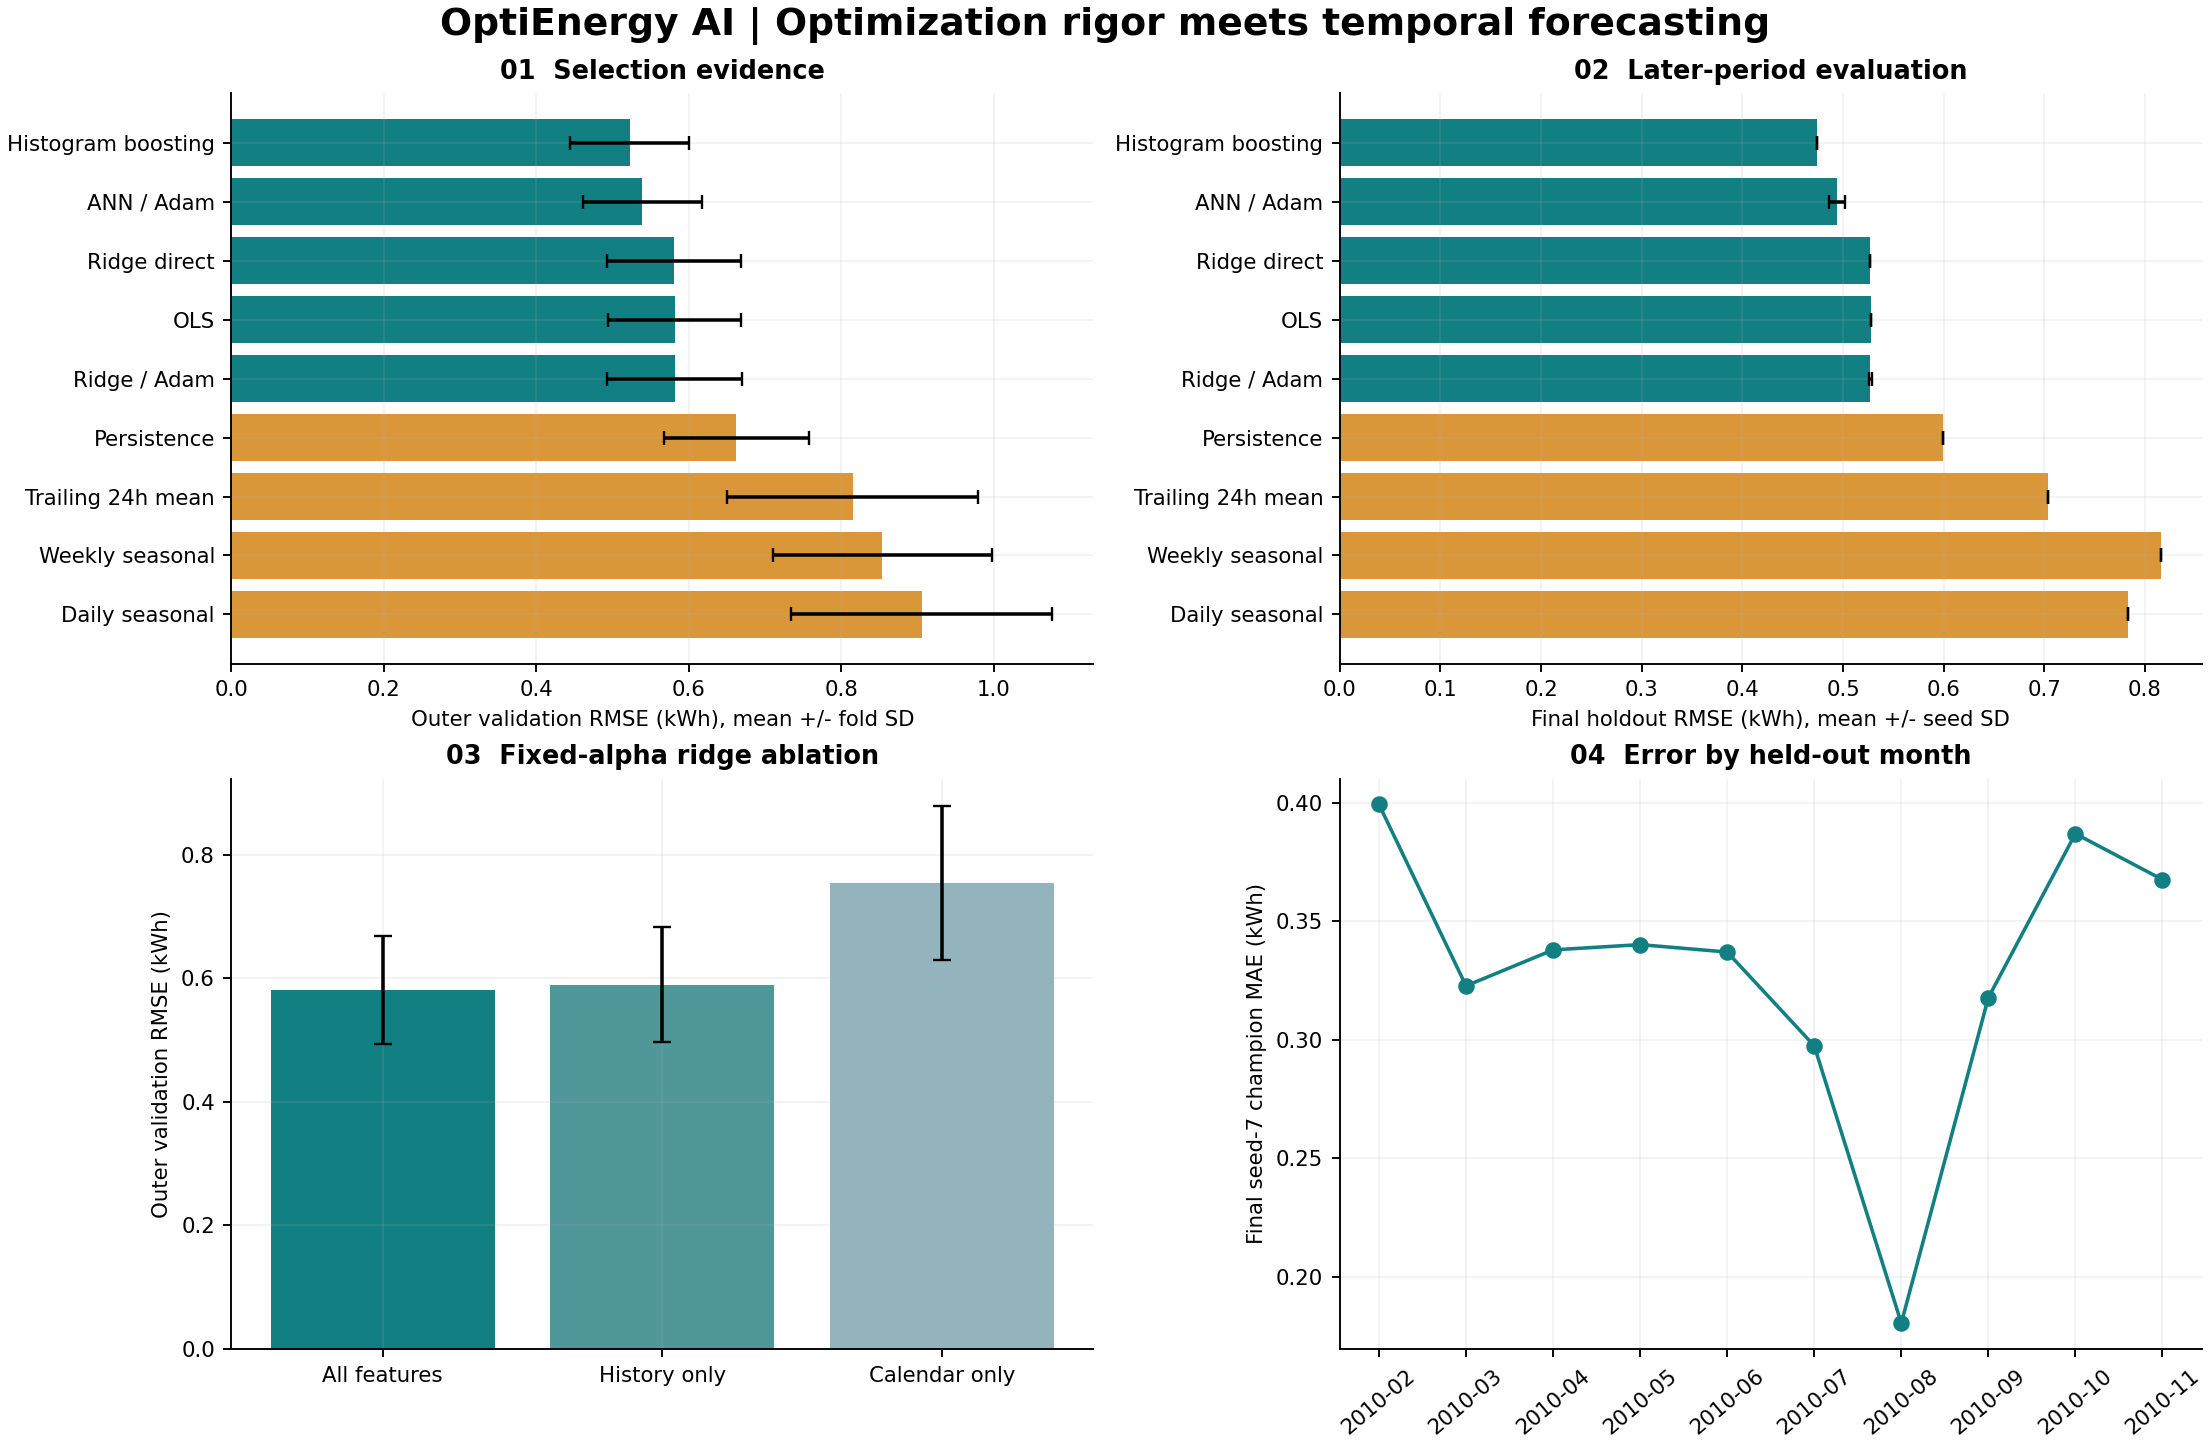

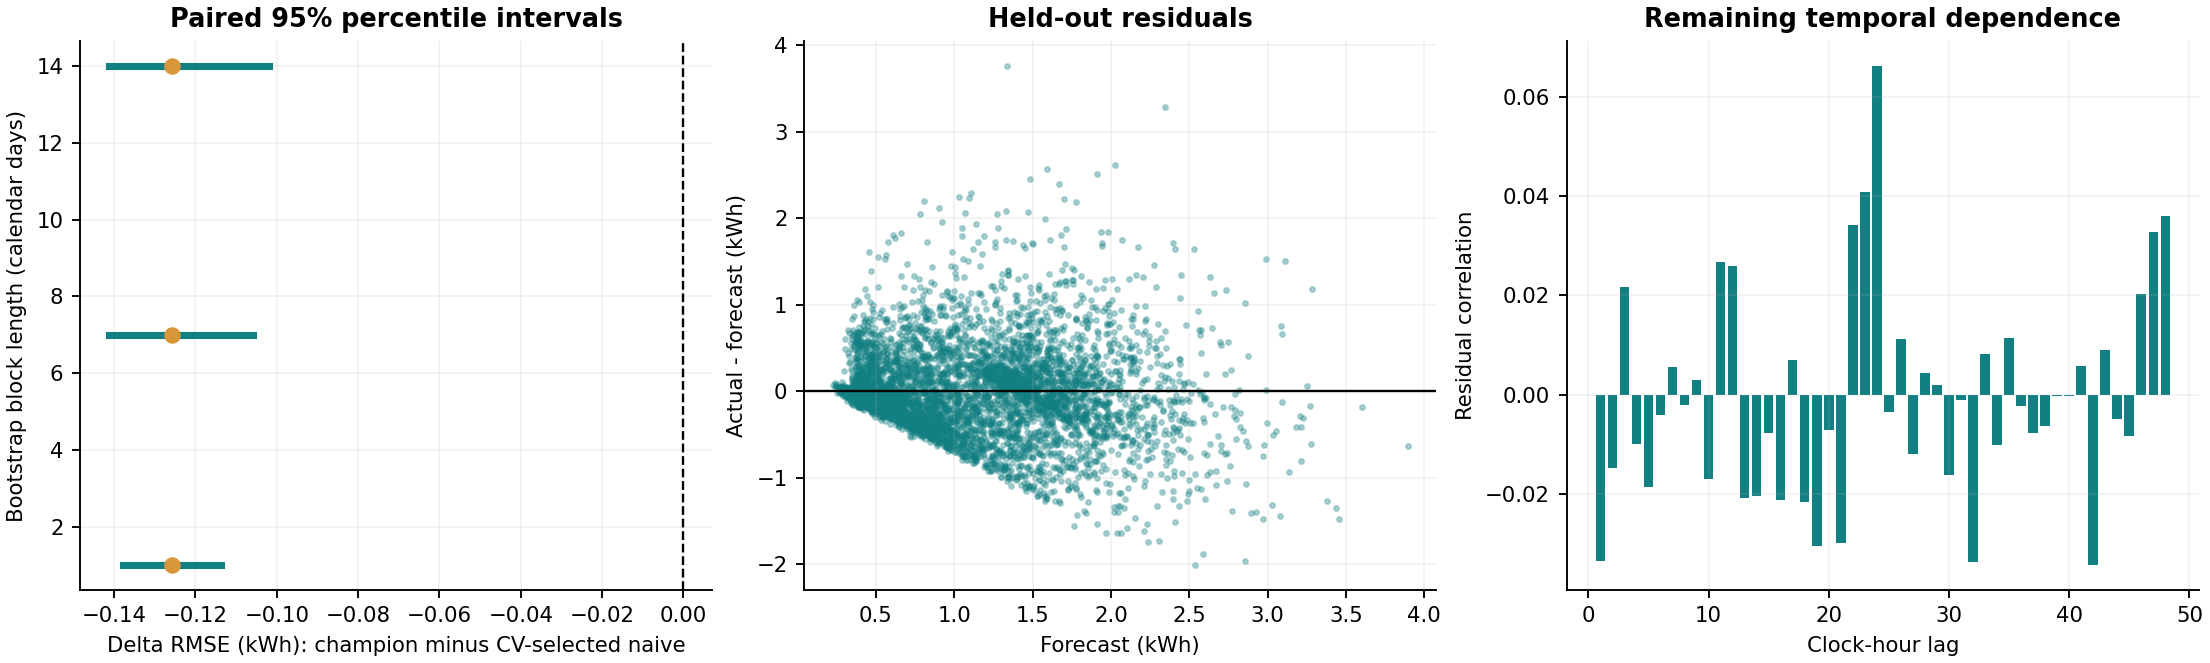

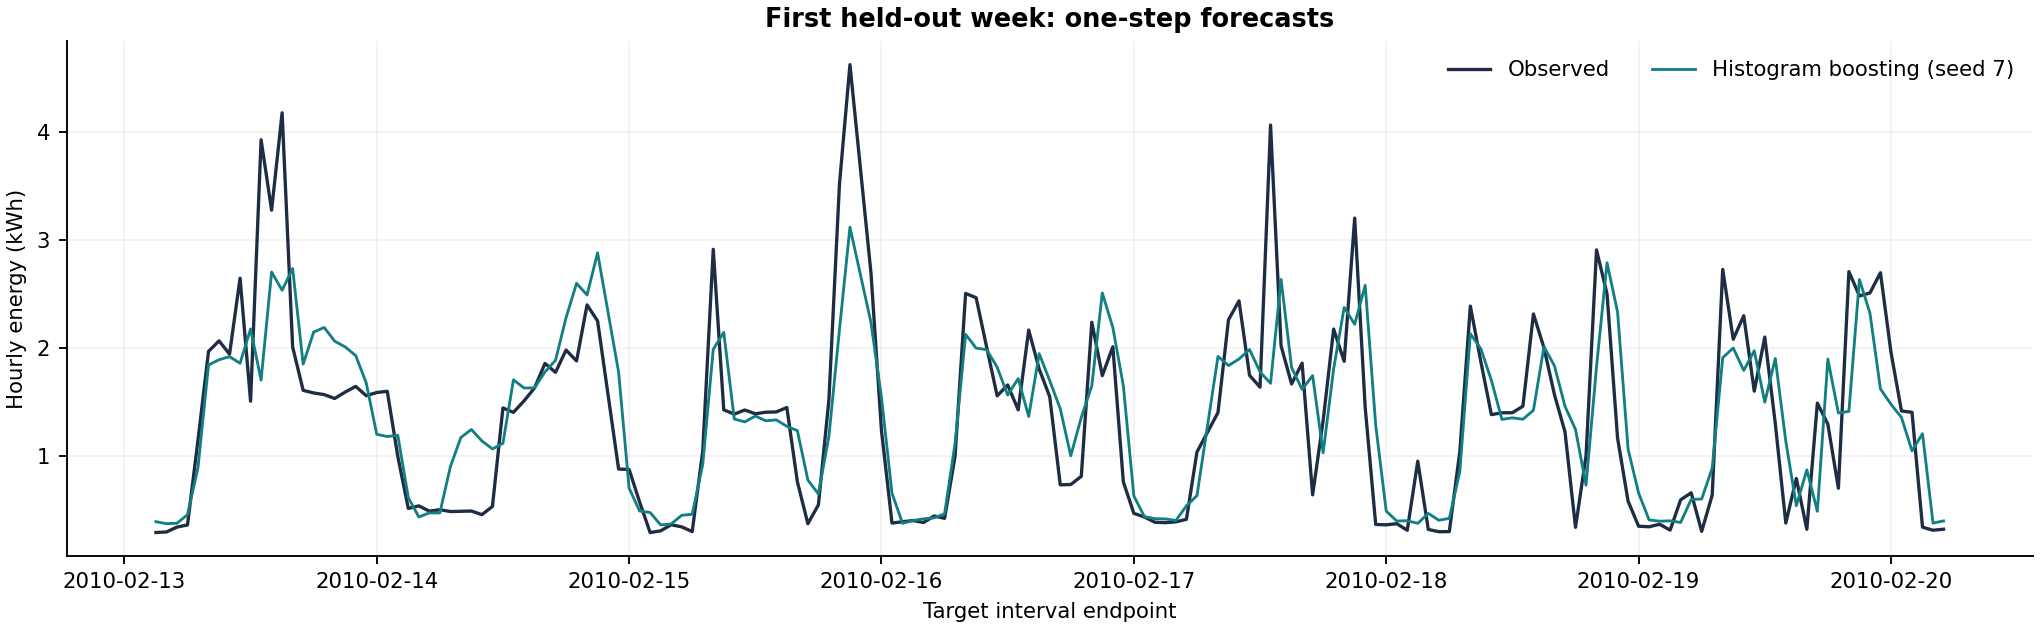

,fold,feature_group,features,mse,rmse,mae,r2
0,1,All features,26,0.409907,0.640239,0.465999,0.500231
1,1,History only,15,0.422140,0.649723,0.464962,0.485315
2,1,Calendar only,11,0.704283,0.839216,0.664812,0.141319
3,2,All features,26,0.230494,0.480098,0.338619,0.448309
4,2,History only,15,0.233831,0.483561,0.338467,0.440321
5,2,Calendar only,11,0.372777,0.610554,0.485415,0.107752
6,3,All features,26,0.387923,0.622835,0.455891,0.544388
7,3,History only,15,0.406116,0.637273,0.461489,0.523020
8,3,Calendar only,11,0.661904,0.813575,0.644332,0.222600


In [28]:
portfolio_figures(portfolio_output)
findings = evidence_cards(portfolio_output, dataset_metadata,
                          notebook_test_result.testsRun, portfolio_test_result.testsRun)
display(Markdown(findings))
for name in ["portfolio_overview.png", "uncertainty_and_residuals.png", "heldout_forecasts.png"]:
    display(NotebookImage(filename=str(portfolio_output / "figures" / name)))
display(pd.read_csv(portfolio_output / "feature_ablation.csv"))

## 25. Honest interpretation of uncertainty and remaining error

The percentile interval resamples **paired overlapping calendar-day blocks** of squared errors and counts. Missing calendar days stay in the grid; within-day error contributions stay together. Negative delta RMSE favors the selected family. Results for 1-, 7- and 14-day blocks disclose sensitivity to dependence assumptions. These approximate intervals assume sufficient local stability, omit training-sample uncertainty, and are not per-forecast prediction intervals. Residual correlation and monthly error can reveal remaining structure without authorizing test-driven reselection.

## 26. Historical forecasting with the selected model

This demonstration uses the fixed deployment seed and a valid held-out origin. It truncates history before computing any feature. Actual future observations are displayed only for comparison; recursive horizons use previous predictions. The benchmark is one-step; the optional 24-hour extension has not been independently validated as a multi-horizon model.

,origin,target_time,horizon,predicted_kwh,actual_kwh
0,2010-02-13 02:00:00,2010-02-13 03:00:00,1,0.387296,0.286967
1,2010-02-13 02:00:00,2010-02-13 04:00:00,2,0.434941,0.292133
2,2010-02-13 02:00:00,2010-02-13 05:00:00,3,0.452663,0.337200
3,2010-02-13 02:00:00,2010-02-13 06:00:00,4,0.513916,0.357167
4,2010-02-13 02:00:00,2010-02-13 07:00:00,5,1.079644,1.142933
5,2010-02-13 02:00:00,2010-02-13 08:00:00,6,1.866102,1.964000
6,2010-02-13 02:00:00,2010-02-13 09:00:00,7,1.901566,2.061967
7,2010-02-13 02:00:00,2010-02-13 10:00:00,8,1.836628,1.938633
8,2010-02-13 02:00:00,2010-02-13 11:00:00,9,1.841764,2.642600
9,2010-02-13 02:00:00,2010-02-13 12:00:00,10,1.889781,1.502867


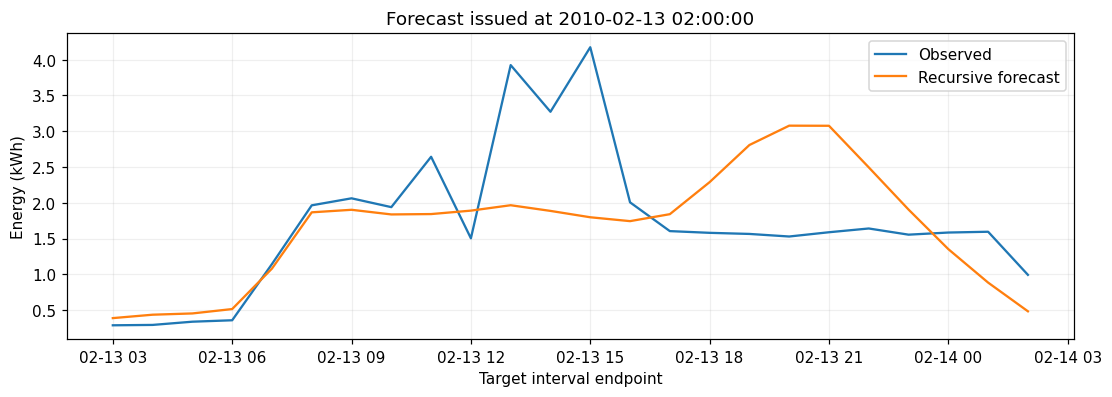

In [29]:
trusted_champion = joblib.load(portfolio_output / "trusted_champion.joblib")  # Our own artifact only.
origin = forecasting_predictions.origin.iloc[0]
prediction_example = forecast_portfolio(trusted_champion, hourly, origin, horizon=24)
display(prediction_example)
figure, axis = plt.subplots(figsize=(10, 3.5), layout="constrained")
axis.plot(prediction_example.target_time, prediction_example.actual_kwh, label="Observed")
axis.plot(prediction_example.target_time, prediction_example.predicted_kwh, label="Recursive forecast")
axis.set(title=f"Forecast issued at {origin}", ylabel="Energy (kWh)", xlabel="Target interval endpoint")
axis.legend()
plt.show()
prediction_example.to_csv(portfolio_output / "recursive_example.csv", index=False)

## 27. Optimization geometry: static figures and optional interaction

Static trajectories render directly on GitHub. All methods use exact benchmark gradients here; SGD and mini-batch GD therefore reduce to GD. Gradient arrows in the optional Plotly view are normalized negative gradients. Non-finite trajectories stop gracefully; paths may leave the displayed range.

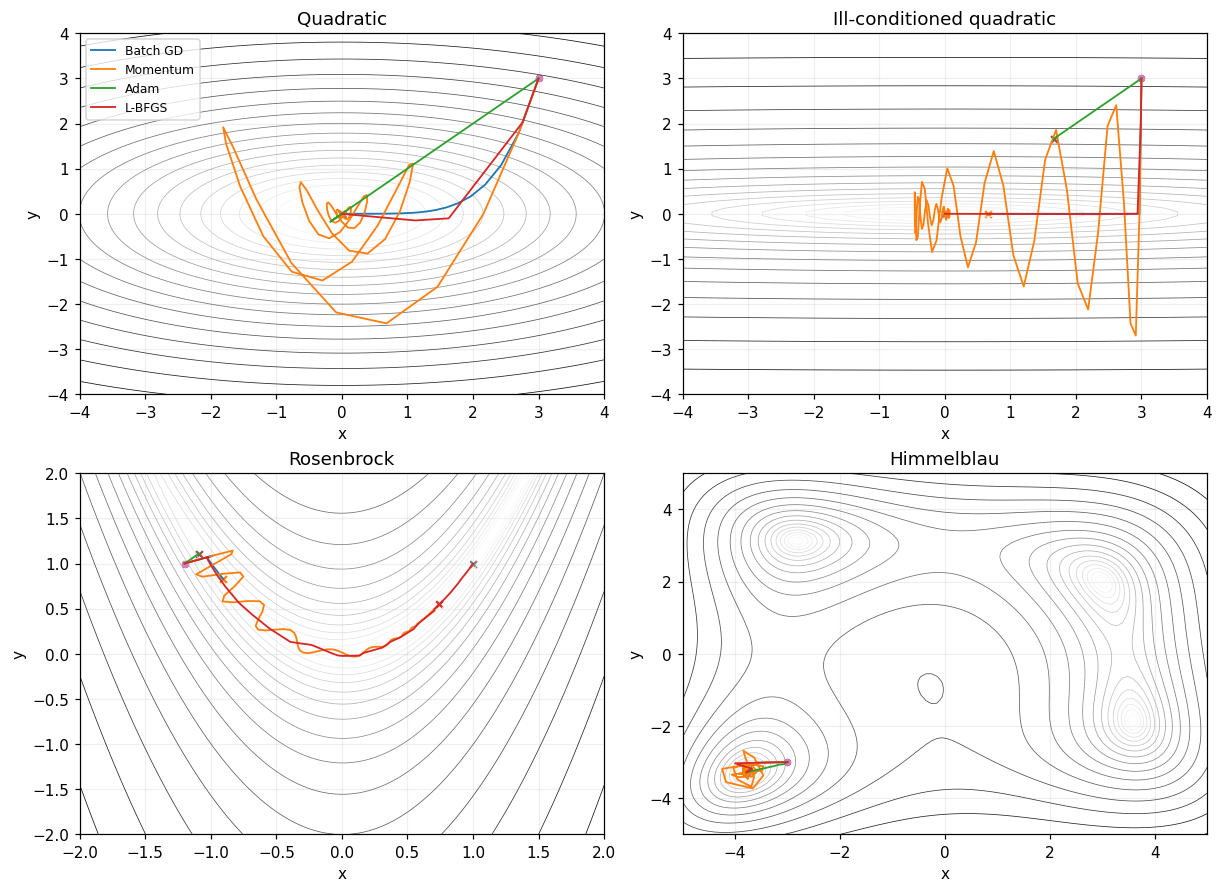

In [30]:
figure, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
for axis, (name, (function, bounds, start, step_size)) in zip(axes.flat, BENCHMARKS.items()):
    grid = np.linspace(*bounds, 100)
    xx, yy = np.meshgrid(grid, grid)
    zz, _ = function([xx, yy])
    axis.contour(xx, yy, np.log1p(zz), levels=18, cmap="Greys", linewidths=.5)
    for method in ["Batch GD", "Momentum", "Adam", "L-BFGS"]:
        path = trajectory(name, method, step_size, steps=150)
        axis.plot(path[:, 0], path[:, 1], label=method, linewidth=1.2)
        axis.scatter(path[0, 0], path[0, 1], marker="o", s=14)
        axis.scatter(path[-1, 0], path[-1, 1], marker="x", s=20)
    axis.set(xlim=bounds, ylim=bounds, title=name, xlabel="x", ylabel="y")
axes[0, 0].legend(fontsize=8)
plt.show()

SHOW_INTERACTIVE = False  # Enable in a running notebook for Plotly 2D/3D/animation.
if SHOW_INTERACTIVE:
    name = "Rosenbrock"
    paths = {method: trajectory(name, method, BENCHMARKS[name][3])
             for method in ["Batch GD", "Momentum", "Adam", "L-BFGS"]}
    landscape(name, paths, animate=True).show()
    landscape(name, paths, three_d=True).show()

## 28. Reproducibility, outputs, and limitations

Generated files are in `OptiEnergy_Notebook_Work/results/`. `temporal_benchmark/` contains the frozen protocol/selection, cross-validation runs, final holdout scores/predictions, feature ablation, bootstrap intervals, error slices, figures, findings, model card and data card. The optimizer lab has its own histories and leaderboard in `demo/`. Runtime caches and trusted model binaries are not intended for GitHub.

**What this project demonstrates:** analytic differentiation; reusable optimization code; fair accounting of training and monitoring work; causal feature construction; temporal model selection distinct from checkpoint selection; reference baselines; failure analysis; reproducible experiments; and communication of uncertainty and limitations.

**What it cannot establish:** performance for other households; causal effects of input features; exact confidence coverage under temporal distribution changes; calibrated individual prediction intervals; production readiness; or universal superiority of any optimizer. The full multi-year *optimizer grid* is not the same experiment as the executed later-period forecasting benchmark.

**Next scientific steps:** evaluate additional households, add weather/occupancy where ethically available, preregister an external test period, equalize tuning resources across model families, and directly evaluate multi-horizon forecasts.

References: [UCI data](https://doi.org/10.24432/C58K54), [Adam](https://arxiv.org/abs/1412.6980), [SciPy L-BFGS-B](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html), [PyTorch optimizers](https://docs.pytorch.org/docs/stable/optim.html), [scikit-learn forecasting evaluation](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html).